# SIC Capstone — Cat vs Dog Image Classification
## Consolidated master notebook (Phases 1 and 3–9)

This notebook combines the uploaded Cat-vs-Dog project notebooks in chronological order. It preserves the original code and Markdown cells rather than inventing training results.

### Before running
- Run this notebook from top to bottom in the DGX environment.
- The project root is expected at `/workspace/sic_final_project`.
- The original dataset and model weights must be present at the paths expected by the source cells.
- Some phases depend on files and variables created by earlier phases.
- Training cells may take a long time and use the GPU.
- Do not use QUICK/test settings when you intend to produce final trained checkpoints.

### Source completeness note
The uploaded file named `02_cnn_mobilenetv2(2).ipynb` is a separate **lung-image classification** project (TensorFlow/MobileNetV2), not this Cat-vs-Dog project. It is deliberately excluded to avoid mixing unrelated datasets, labels, models and results. The correct Cat-vs-Dog Phase 2 notebook (likely EDA, if that is how your phases are numbered) was not among the supplied files. Phases 1 and 3–9 are included below.

### Final exports
The final cell creates:
1. `results/complete_project_results.zip` — one archive containing saved result artefacts (metrics, CSVs, plots, reports and deployment package where present), plus an index.
2. `trained_models_and_pretrained_weights.tar.gz` — a separate archive of the `models/` directory and `app_package/` if present.

These archives are created on the DGX project filesystem. They do not upload or download themselves.

---
# Phase 1 — Problem understanding
Original source: `01_problem_understanding.ipynb`

The following cells are preserved from the uploaded notebook.

In [1]:
import os
# The container is limited to 8 CPUs, but the host reports 224 cores.
# Cap thread pools BEFORE importing numpy/sklearn/torch to avoid oversubscription.
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "8"

import random
import numpy as np
import torch
from pathlib import Path

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(8)

# Absolute path, because Jupyter's working directory changes inside notebooks/
PROJECT_ROOT = Path("/workspace/sic_final_project")
DATASET_DIR = PROJECT_ROOT / "Cats and Dogs Classification Dataset"
print("Dataset dir exists:", DATASET_DIR.is_dir())

Dataset dir exists: True


In [2]:
%pip install seaborn==0.13.2 scikit-image==0.25.2 imagehash==4.3.2

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.8/14.8 MB 750.6 kB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 660.9 kB/s eta 0:00:00a 0:00:01

[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import seaborn, skimage, imagehash, pandas, sklearn, PIL
print("new:", seaborn.__version__, skimage.__version__, imagehash.__version__)
print("unchanged?:", np.__version__, pandas.__version__, sklearn.__version__, PIL.__version__)

new: 0.13.2 0.25.2 4.3.2
unchanged?: 1.24.4 2.2.2 1.5.2 10.4.0


In [4]:
from collections import Counter

print("Top level of dataset folder:")
for item in sorted(DATASET_DIR.iterdir()):
    print("  ", "[dir] " if item.is_dir() else "[file]", item.name)

for class_name in ["Cat", "Dog"]:
    files = [p for p in (DATASET_DIR / class_name).rglob("*") if p.is_file()]
    exts = Counter(p.suffix.lower() for p in files)
    print(f"\n{class_name}: {len(files)} files | extensions: {dict(exts)}")

!ls -la ~/.cache/torch/hub/checkpoints 2>/dev/null || echo "no cached pretrained weights"

Top level of dataset folder:
   [dir]  Cat
   [dir]  Dog

Cat: 12499 files | extensions: {'.jpg': 12499}

Dog: 12499 files | extensions: {'.jpg': 12499}
no cached pretrained weights


---
# Phase 2 — Source notebook not supplied

The uploaded `02_cnn_mobilenetv2(2).ipynb` is about lung-image classification, so it has not been inserted here. Please provide the correct Cat-vs-Dog Phase 2 notebook if you want this phase included.

---
# Phase 3 — Data cleaning
Original source: `03_data_cleaning.ipynb`

The following cells are preserved from the uploaded notebook.

In [1]:
import os
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "8"
import sys, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED)
PROJECT_ROOT = Path("/workspace/sic_final_project")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%%writefile -a /workspace/sic_final_project/src/data_processing.py


# ---------------- Phase 3: integrity, duplicates ----------------
import hashlib
import numpy as np
import imagehash
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components


def inspect_image(path) -> dict:
    """FULLY decode one image. Returns integrity status, content hashes and
    32x32 grayscale statistics. Never raises: failures are recorded, not hidden."""
    rec = {"path": str(path), "decode_ok": False, "decode_error": None,
           "md5": None, "phash": None, "thumb_std": None, "thumb_mean": None}
    try:
        rec["md5"] = hashlib.md5(Path(path).read_bytes()).hexdigest()   # exact-duplicate fingerprint
        with Image.open(path) as img:
            img.load()                       # force the full pixel decode (catches truncated files)
            rgb = img.convert("RGB")         # standardise P / L / CMYK / RGBA -> RGB
        rec["phash"] = str(imagehash.phash(rgb))   # perceptual fingerprint (near-duplicates)
        thumb = np.asarray(rgb.convert("L").resize((32, 32)), dtype=np.float32)
        rec["thumb_std"], rec["thumb_mean"] = float(thumb.std()), float(thumb.mean())
        rec["decode_ok"] = True
    except Exception as exc:
        rec["decode_error"] = f"{type(exc).__name__}: {exc}"[:120]
    return rec


POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)


def near_duplicate_pairs(hex_hashes, max_distance=4, chunk=256):
    """All index pairs (i<j) whose 64-bit perceptual hashes differ in <= max_distance bits."""
    H = np.array([np.frombuffer(bytes.fromhex(h), dtype=np.uint8) for h in hex_hashes])
    pairs = []
    for start in range(0, len(H), chunk):
        block = H[start:start + chunk]
        dist = POPCOUNT[block[:, None, :] ^ H[None, :, :]].sum(axis=2, dtype=np.uint16)
        rows, cols = np.nonzero(dist <= max_distance)
        rows = rows + start
        keep = cols > rows
        pairs.append(np.column_stack([rows[keep], cols[keep]]))
    return np.vstack(pairs)


def group_ids_from_pairs(n_items, pairs):
    """Connected components: items linked by near-duplicate pairs share a group id."""
    graph = csr_matrix((np.ones(len(pairs)), (pairs[:, 0], pairs[:, 1])), shape=(n_items, n_items))
    return connected_components(graph, directed=False)[1]

Appending to /workspace/sic_final_project/src/data_processing.py


In [3]:
import importlib, data_processing
importlib.reload(data_processing)

raw = pd.read_csv(PROJECT_ROOT / "data/metadata/metadata_raw.csv")
t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as pool:
    integ = pd.DataFrame(list(tqdm(pool.map(data_processing.inspect_image, raw["path"]), total=len(raw))))
print(f"Inspected {len(integ):,} images in {time.time()-t0:.0f}s")

meta = raw.drop(columns=["error"]).merge(integ, on="path")
meta.to_csv(PROJECT_ROOT / "data/metadata/metadata_inspected.csv", index=False)

bad = meta[~meta["decode_ok"]]
print("\nQ16 - corrupted / unreadable files:", len(bad))
display(bad[["path", "label", "pil_format", "decode_error"]].head(20))

 96%|███████████████████████████████████████▏ | 23920/24998 [01:08<00:03, 354.63it/s]/usr/local/lib/python3.10/dist-packages/PIL/TiffImagePlugin.py:900: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|█████████████████████████████████████████| 24998/24998 [01:11<00:00, 349.79it/s]


Inspected 24,998 images in 72s

Q16 - corrupted / unreadable files: 0


,path,label,pil_format,decode_error


In [4]:
mismatch = meta[(meta["extension"] == ".jpg") & (meta["pil_format"] != "JPEG")]
print("Files named .jpg but not JPEG inside:", len(mismatch))
print(pd.crosstab(mismatch["pil_format"], mismatch["label"]))

Files named .jpg but not JPEG inside: 229
label       Cat  Dog
pil_format          
BMP          71  102
GIF          22   29
PNG           0    4
PSD           1    0


Exact-duplicate files (in a group of 2+): 58 | extra copies: 30
Exact-duplicate groups with BOTH labels (label conflict): 2

Near-duplicate pairs: 39 (computed in 27s)
Images in a near-duplicate group: 70 | groups: 34 | largest group: 4
Near-duplicate groups with BOTH labels: 2


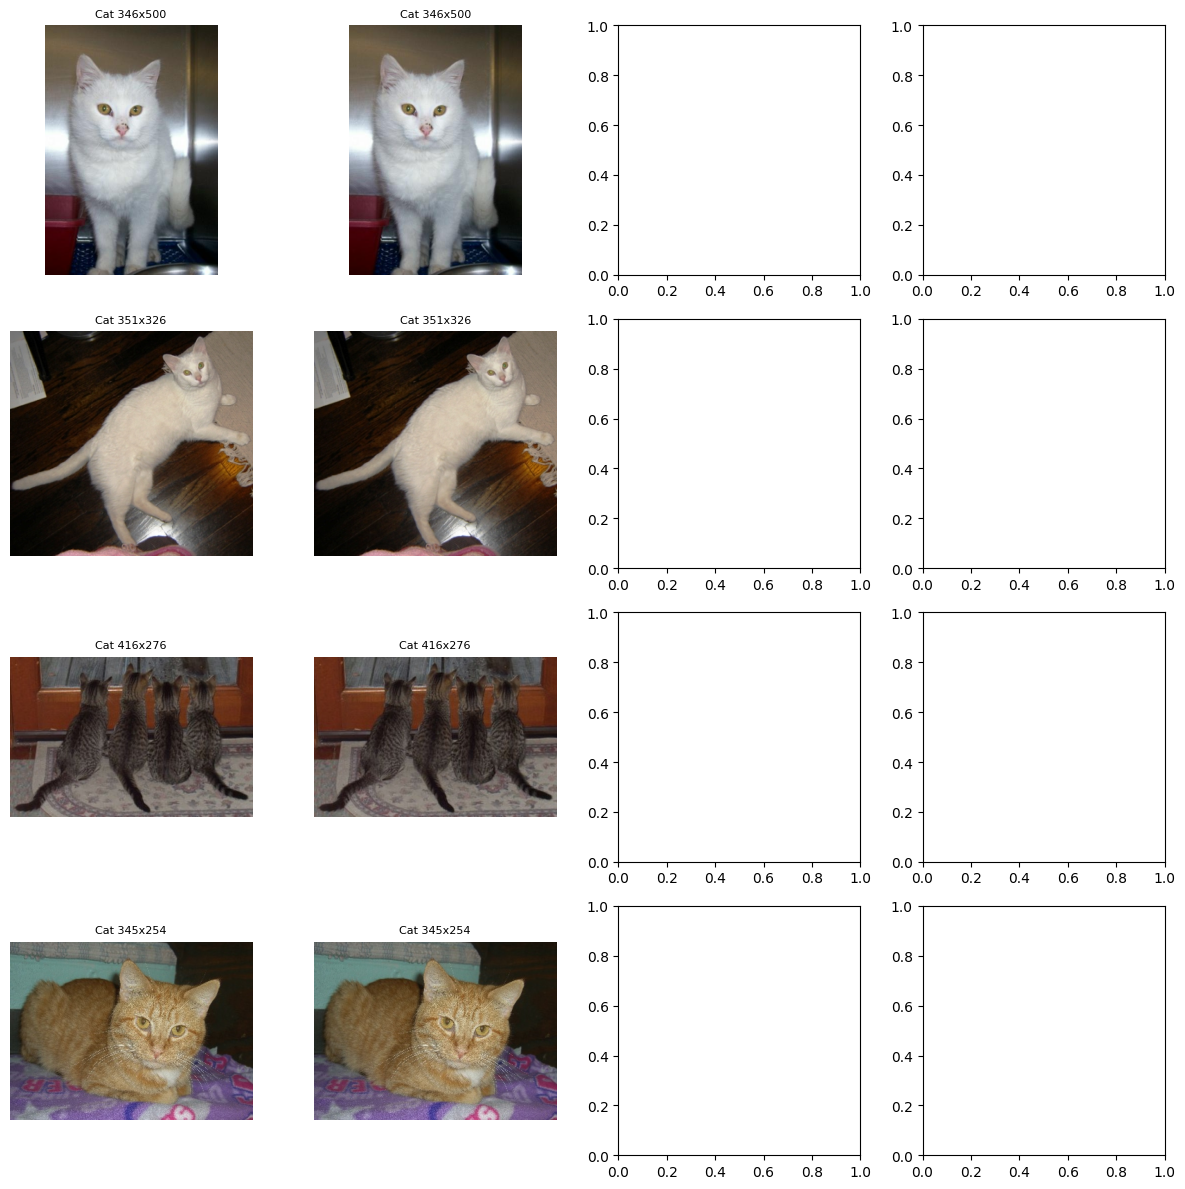

In [5]:
good = meta[meta["decode_ok"]].reset_index(drop=True)

# (a) exact duplicates: byte-identical files
exact_sizes = good.groupby("md5")["path"].transform("size")
print("Exact-duplicate files (in a group of 2+):", (exact_sizes > 1).sum(),
      "| extra copies:", (good.duplicated("md5")).sum())
cross = good.groupby("md5")["label"].nunique()
print("Exact-duplicate groups with BOTH labels (label conflict):", (cross > 1).sum())

# (b) near duplicates: perceptual hash within 4 of 64 bits
t0 = time.time()
pairs = data_processing.near_duplicate_pairs(good["phash"].tolist(), max_distance=4)
good["group_id"] = data_processing.group_ids_from_pairs(len(good), pairs)
gsize = good.groupby("group_id")["path"].transform("size")
print(f"\nNear-duplicate pairs: {len(pairs)} (computed in {time.time()-t0:.0f}s)")
print("Images in a near-duplicate group:", (gsize > 1).sum(),
      "| groups:", good.loc[gsize > 1, "group_id"].nunique(),
      "| largest group:", gsize.max())
near_cross = good.groupby("group_id")["label"].nunique()
print("Near-duplicate groups with BOTH labels:", (near_cross > 1).sum())

# visual check of the first few duplicate groups
multi = good[gsize > 1].groupby("group_id")
shown = 0
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for _, g in multi:
    if shown >= 4: break
    for ax, (_, row) in zip(axes[shown], g.head(4).iterrows()):
        with Image.open(row["path"]) as im: ax.imshow(im.convert("RGB"))
        ax.set_title(f"{row['label']} {row['width']}x{row['height']}", fontsize=8); ax.axis("off")
    shown += 1
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/03_duplicate_groups.png", dpi=110); plt.show()

min side < 16 / 32 / 64 px: [1, 1, 43]
extreme aspect > 2.5 / 3 / 4: [33, 5, 1]
file size < 1 KB / 2 KB: [3, 52] | > 500 KB: 21
near-uniform (32x32 gray std) < 2 / 5: [1, 1]


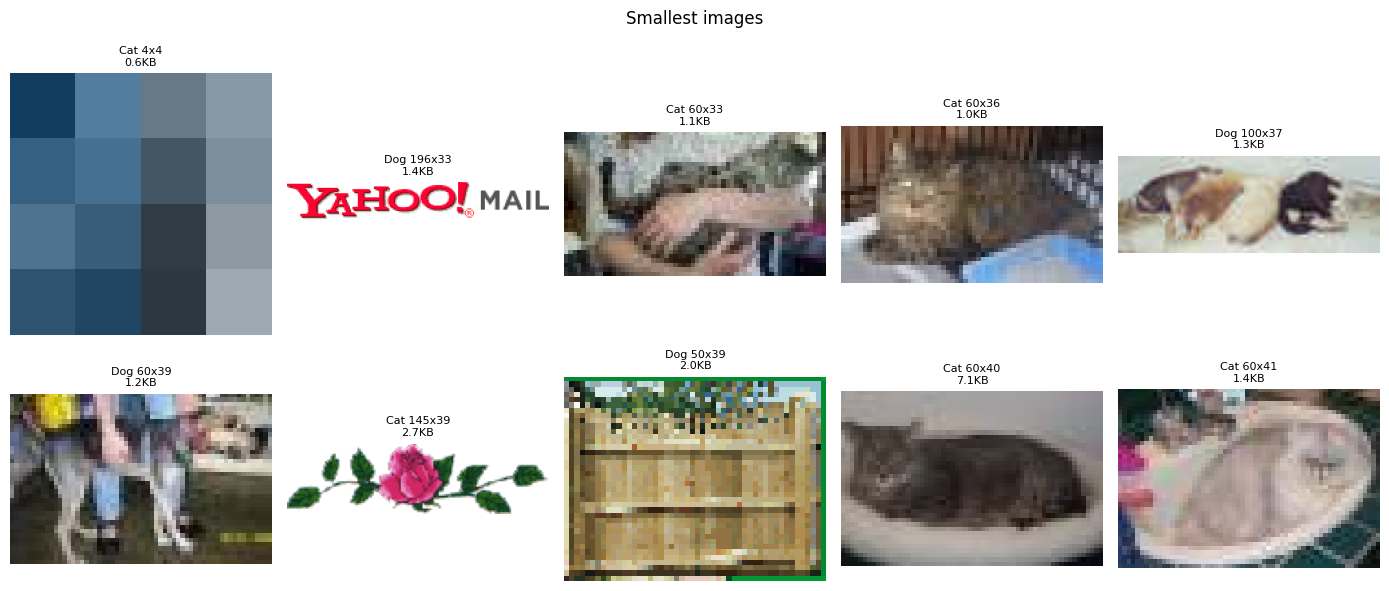

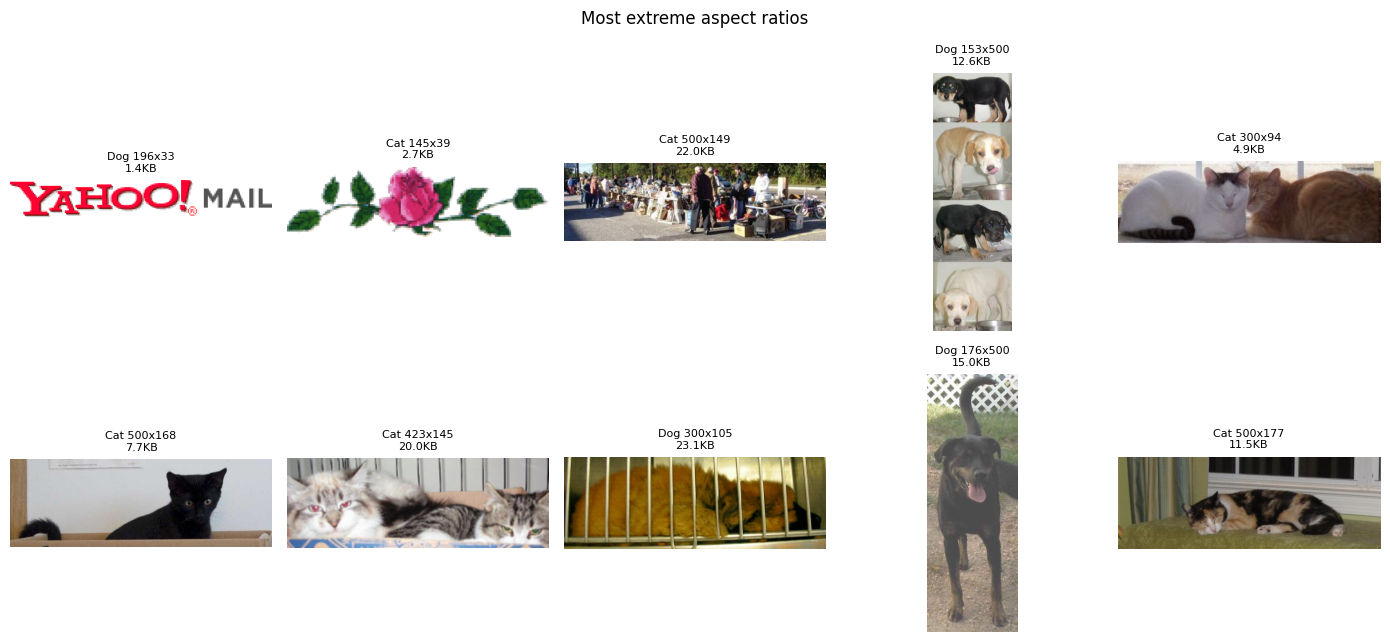

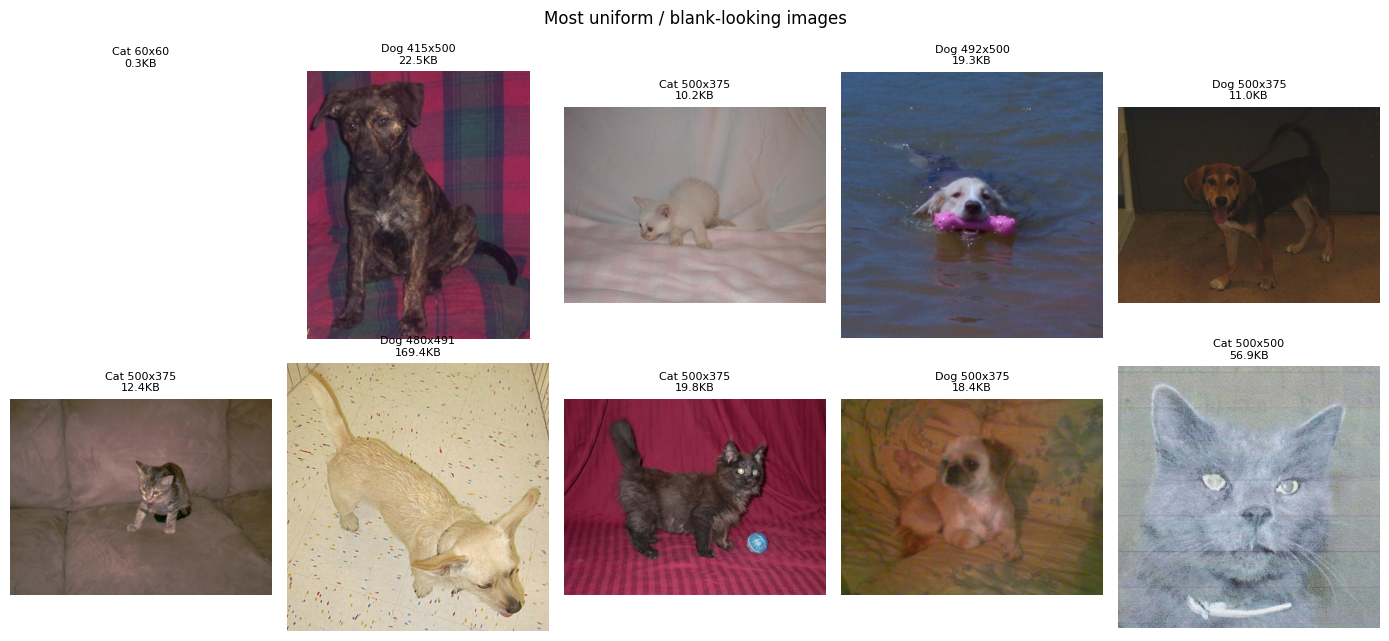

In [6]:
good["min_side"] = good[["width", "height"]].min(axis=1)
good["aspect_ext"] = np.maximum(good["width"] / good["height"], good["height"] / good["width"])

print("min side < 16 / 32 / 64 px:", [(good["min_side"] < t).sum() for t in (16, 32, 64)])
print("extreme aspect > 2.5 / 3 / 4:", [(good["aspect_ext"] > t).sum() for t in (2.5, 3, 4)])
print("file size < 1 KB / 2 KB:", [(good["file_size_kb"] < t).sum() for t in (1, 2)], "| > 500 KB:", (good["file_size_kb"] > 500).sum())
print("near-uniform (32x32 gray std) < 2 / 5:", [(good["thumb_std"] < t).sum() for t in (2, 5)])

def montage(df_, title, n=10):
    sub = df_.head(n)
    fig, axes = plt.subplots(2, 5, figsize=(14, 6.5))
    for ax in axes.ravel(): ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), sub.iterrows()):
        with Image.open(r["path"]) as im: ax.imshow(im.convert("RGB"))
        ax.set_title(f"{r['label']} {r['width']}x{r['height']}\n{r['file_size_kb']:.1f}KB", fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

montage(good.sort_values("min_side"), "Smallest images")
montage(good.sort_values("aspect_ext", ascending=False), "Most extreme aspect ratios")
montage(good.sort_values("thumb_std"), "Most uniform / blank-looking images")

In [7]:
print(pd.crosstab(good["mode"], good["pil_format"]))

pil_format  BMP  GIF   JPEG  PNG  PSD
mode                                 
CMYK          0    0      3    0    0
L             0    0      5    0    0
P             5   51      0    1    0
RGB         168    0  24761    1    1
RGBA          0    0      0    2    0


In [8]:
MIN_SIDE = 32          # drop images with a side shorter than this (judgement call: check against Cell 6)
MIN_THUMB_STD = 2.0    # drop near-uniform (blank-looking) images

log = []

# 1) Files that failed the full decode (these are not in `good`)
for p, e in zip(bad["path"], bad["decode_error"]):
    log.append({"path": p, "reason": f"corrupted: {e}"})

# 2) Rules applied to the readable images. Each helper only logs files not already excluded.
def drop(mask, reason):
    already = {r["path"] for r in log}
    for p in good.loc[mask, "path"]:
        if p not in already:
            log.append({"path": p, "reason": reason})

conflict_md5 = cross[cross > 1].index        # byte-identical files that carry BOTH labels
drop(good["md5"].isin(conflict_md5), "exact duplicate with conflicting labels")
drop(good["min_side"] < MIN_SIDE, f"tiny image (min side < {MIN_SIDE})")
drop(good["thumb_std"] < MIN_THUMB_STD, "near-uniform image")
drop(good.duplicated("md5", keep="first"), "exact duplicate (extra copy)")

cleaning_log = pd.DataFrame(log, columns=["path", "reason"]).drop_duplicates("path")
cleaning_log.to_csv(PROJECT_ROOT / "data/metadata/cleaning_log.csv", index=False)

clean = good[~good["path"].isin(cleaning_log["path"])].copy()
clean["label_id"] = clean["label"].map({"Cat": 0, "Dog": 1})
keep_cols = ["path", "label", "label_id", "width", "height", "mode",
             "pil_format", "md5", "phash", "group_id"]
clean[keep_cols].to_csv(PROJECT_ROOT / "data/metadata/metadata_clean.csv", index=False)

print("Original:", len(meta), "| excluded:", len(cleaning_log), "| remaining:", len(clean))
print("\nExclusion reasons:")
print(cleaning_log["reason"].str.split(":").str[0].value_counts())
print("\nClass balance after cleaning:")
print(clean["label"].value_counts())
print(clean["label"].value_counts(normalize=True).round(4))

Original: 24998 | excluded: 34 | remaining: 24964

Exclusion reasons:
reason
exact duplicate (extra copy)               26
exact duplicate with conflicting labels     6
tiny image (min side < 32)                  1
near-uniform image                          1
Name: count, dtype: int64

Class balance after cleaning:
label
Dog    12486
Cat    12478
Name: count, dtype: int64
label
Dog    0.5002
Cat    0.4998
Name: proportion, dtype: float64


---
# Phase 4 — Preprocessing
Original source: `04_preprocessing(1).ipynb`

The following cells are preserved from the uploaded notebook.

In [1]:
import os
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "8"
import sys, json, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED)
PROJECT_ROOT = Path("/workspace/sic_final_project")
for d in ["data/processed", "data/splits"]:
    (PROJECT_ROOT / d).mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

LABEL_MAP = {"Cat": 0, "Dog": 1}
clean = pd.read_csv(PROJECT_ROOT / "data/metadata/metadata_clean.csv")
print(len(clean), clean["label"].value_counts().to_dict())

24964 {'Dog': 12486, 'Cat': 12478}


In [2]:
%%writefile -a /workspace/sic_final_project/src/data_processing.py


# ---------------- Phase 4: preprocessing and splitting ----------------
from sklearn.model_selection import StratifiedGroupKFold


def load_rgb(path):
    """Decode ANY supported image and standardise to 3-channel RGB (handles P, L, CMYK, RGBA)."""
    with Image.open(path) as img:
        img.load()
        return img.convert("RGB")


def resize_array(rgb_img, size):
    """Resize (stretching to a square) and return a uint8 array of shape (size, size, 3)."""
    return np.asarray(rgb_img.resize((size, size), Image.BILINEAR), dtype=np.uint8)


def _load_multi(path, sizes):
    rgb = load_rgb(path)
    return [resize_array(rgb, s) for s in sizes]


def build_caches(paths, sizes=(64, 128, 224), n_workers=8):
    """Decode each image ONCE and fill one uint8 array per size, in the order of `paths`."""
    arrays = [np.empty((len(paths), s, s, 3), dtype=np.uint8) for s in sizes]
    with ThreadPoolExecutor(max_workers=n_workers) as pool:
        for i, out in enumerate(pool.map(lambda p: _load_multi(p, sizes), paths)):
            for arr, a in zip(arrays, out):
                arr[i] = a
    return arrays


def make_splits(df, seed=42, n_folds=20, n_test_folds=3, n_val_folds=3):
    """70/15/15 split, stratified by label, near-duplicate groups kept together."""
    sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    fold = np.full(len(df), -1)
    for k, (_, idx) in enumerate(sgkf.split(df, df["label_id"], groups=df["group_id"])):
        fold[idx] = k
    split = np.where(fold < n_test_folds, "test",
            np.where(fold < n_test_folds + n_val_folds, "val", "train"))
    return pd.Series(split, index=df.index, name="split")

Appending to /workspace/sic_final_project/src/data_processing.py


/usr/local/lib/python3.10/dist-packages/PIL/TiffImagePlugin.py:900: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Built caches in 41s

64x64: shape (24964, 64, 64, 3) | dtype uint8 | 0.31 GB | min 0 max 255
128x128: shape (24964, 128, 128, 3) | dtype uint8 | 1.23 GB | min 0 max 255
224x224: shape (24964, 224, 224, 3) | dtype uint8 | 3.76 GB | min 0 max 255


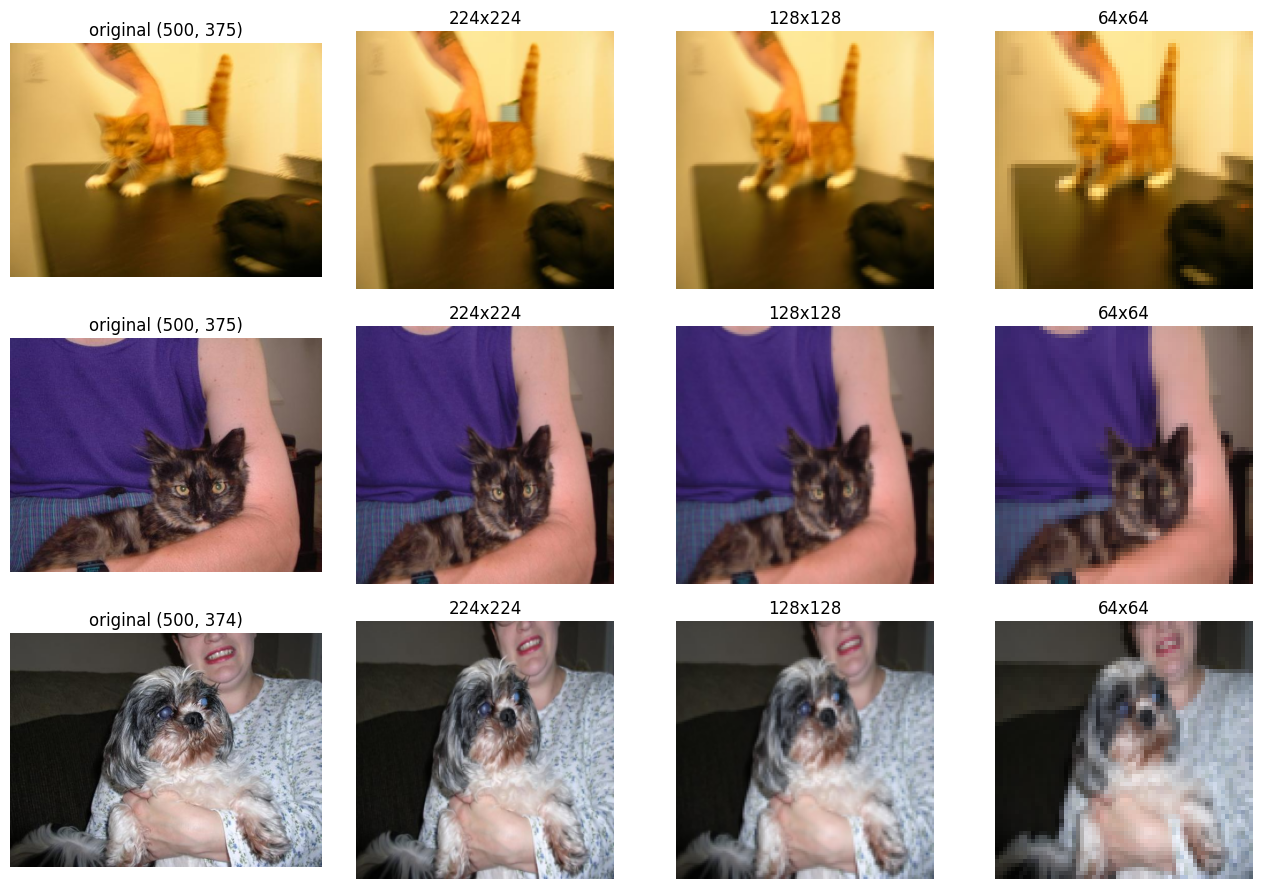

In [3]:
import importlib, data_processing
importlib.reload(data_processing)

t0 = time.time()
a64, a128, a224 = data_processing.build_caches(clean["path"].tolist(), sizes=(64, 128, 224))
print(f"Built caches in {time.time()-t0:.0f}s\n")
for name, arr in [("64", a64), ("128", a128), ("224", a224)]:
    print(f"{name}x{name}: shape {arr.shape} | dtype {arr.dtype} | {arr.nbytes/1e9:.2f} GB | min {arr.min()} max {arr.max()}")

# What resizing does to a few images
fig, ax = plt.subplots(3, 4, figsize=(13, 9))
for row, i in enumerate([0, 5000, 20000]):
    orig = data_processing.load_rgb(clean.loc[i, "path"])
    ax[row, 0].imshow(orig); ax[row, 0].set_title(f"original {orig.size}")
    for a, arr, n in zip(ax[row, 1:], (a224, a128, a64), (224, 128, 64)):
        a.imshow(arr[i]); a.set_title(f"{n}x{n}")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/04_resize_demo.png", dpi=110); plt.show()

In [4]:
batch = a128[:8]
x = batch.astype(np.float32) / 255.0
print("before:", batch.dtype, batch.min(), batch.max(), "| after:", x.dtype, round(float(x.min()), 3), round(float(x.max()), 3))

clean["label_id"] = clean["label"].map(LABEL_MAP)
y = clean["label_id"].to_numpy(dtype=np.int64)
print("\nLabel encoding:", LABEL_MAP)
print(pd.Series(y).value_counts().sort_index().to_dict(), "| y shape:", y.shape)

before: uint8 0 255 | after: float32 0.0 1.0

Label encoding: {'Cat': 0, 'Dog': 1}
{0: 12478, 1: 12486} | y shape: (24964,)


In [5]:
clean["split"] = data_processing.make_splits(clean, seed=SEED)
clean["array_index"] = np.arange(len(clean))      # row number in the cached arrays

print(clean["split"].value_counts())
print("\nShare of the whole dataset:"); print(clean["split"].value_counts(normalize=True).round(4))
print("\nClass counts per split:"); print(pd.crosstab(clean["split"], clean["label"]))
print("\nClass proportions per split:"); print(pd.crosstab(clean["split"], clean["label"], normalize="index").round(4))

# Leakage guard: no file, no identical image, no near-duplicate group in more than one split
for col in ["path", "md5", "group_id"]:
    n = (clean.groupby(col)["split"].nunique() > 1).sum()
    print(f"{col:9s} present in more than one split: {n}")
    assert n == 0

# Q29: what a NAIVE random split would have done with the near-duplicate groups
from sklearn.model_selection import train_test_split
tr_idx, rest_idx = train_test_split(np.arange(len(clean)), test_size=0.30,
                                    stratify=clean["label_id"], random_state=SEED)
naive = np.array(["train"] * len(clean), dtype=object); naive[rest_idx] = "other"
g = pd.DataFrame({"group_id": clean["group_id"], "naive": naive})
group_size = g.groupby("group_id").size()
straddle = g.groupby("group_id")["naive"].nunique() > 1
print("\nNear-duplicate groups (size > 1):", int((group_size > 1).sum()))
print("...split across train and test by a NAIVE random split:", int(((group_size > 1) & straddle).sum()))

split
train    17479
test      3743
val       3742
Name: count, dtype: int64

Share of the whole dataset:
split
train    0.7002
test     0.1499
val      0.1499
Name: proportion, dtype: float64

Class counts per split:
label   Cat   Dog
split            
test   1870  1873
train  8738  8741
val    1870  1872

Class proportions per split:
label     Cat     Dog
split                
test   0.4996  0.5004
train  0.4999  0.5001
val    0.4997  0.5003
path      present in more than one split: 0
md5       present in more than one split: 0
group_id  present in more than one split: 0

Near-duplicate groups (size > 1): 6
...split across train and test by a NAIVE random split: 4


In [6]:
out = PROJECT_ROOT / "data/processed"
np.save(out / "images_64.npy", a64); np.save(out / "images_128.npy", a128)
np.save(out / "images_224.npy", a224); np.save(out / "labels.npy", y)

split_cols = ["array_index", "path", "label", "label_id", "group_id", "md5", "split"]
clean[split_cols].to_csv(PROJECT_ROOT / "data/splits/split_seed42.csv", index=False)

config = {
    "label_map": LABEL_MAP, "seed": SEED, "image_sizes": {"ml": 64, "cnn": 128, "pretrained": 224},
    "resize": "direct resize to square (stretch), PIL BILINEAR", "color": "RGB",
    "storage": "uint8; divide by 255 per batch",
    "imagenet_mean": [0.485, 0.456, 0.406], "imagenet_std": [0.229, 0.224, 0.225],
    "split": "StratifiedGroupKFold(20 folds): 3 test, 3 val, 14 train",
    "n_images": int(len(clean)),
}
(PROJECT_ROOT / "data/processed/preprocessing_config.json").write_text(json.dumps(config, indent=2))

# Cache rows must match the manifest: re-derive 5 random images from disk and compare
rng = np.random.default_rng(SEED)
for i in rng.choice(len(clean), 5, replace=False):
    ref = data_processing.resize_array(data_processing.load_rgb(clean.loc[i, "path"]), 128)
    assert np.array_equal(ref, a128[i])
print("Saved. Cache/manifest alignment check passed.")
!ls -lh /workspace/sic_final_project/data/processed

Saved. Cache/manifest alignment check passed.
total 5.0G
-rw-r--r-- 1 root root 1.2G Nov 17 07:04 images_128.npy
-rw-r--r-- 1 root root 3.5G Nov 17 07:04 images_224.npy
-rw-r--r-- 1 root root 293M Nov 17 07:04 images_64.npy
-rw-r--r-- 1 root root 196K Nov 17 07:04 labels.npy
-rw-r--r-- 1 root root  475 Nov 17 07:04 preprocessing_config.json


---
# Phase 5 — Traditional machine learning
Original source: `05_traditional_ml(1).ipynb`

The following cells are preserved from the uploaded notebook.

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("/workspace/sic_final_project")
needed = ["data/processed/images_64.npy", "data/processed/labels.npy",
          "data/splits/split_seed42.csv", "data/metadata/metadata_clean.csv"]
for rel in needed:
    print(f"{'OK     ' if (PROJECT_ROOT / rel).exists() else 'MISSING'} {rel}")

for d in ["src", "models/traditional", "results/figures", "results/metrics", "results/comparisons"]:
    (PROJECT_ROOT / d).mkdir(parents=True, exist_ok=True)

split_df = pd.read_csv(PROJECT_ROOT / "data/splits/split_seed42.csv")
ok = split_df["path"].map(lambda p: Path(p).exists()).sum()
print(f"Image paths in split file that exist: {ok} / {len(split_df)}")

gi = PROJECT_ROOT / ".gitignore"
if not gi.exists():
    gi.write_text("Cats and Dogs Classification Dataset/\n*.zip\ndata/processed/\nmodels/\n"
                  "*.npy\n*.joblib\n*.pth\n*.pt\n.ipynb_checkpoints/\n__pycache__/\n")
    print(".gitignore created")
else:
    print(".gitignore already exists (left unchanged)")

In [ ]:
%%writefile /workspace/sic_final_project/src/evaluation.py
"""Shared evaluation helpers (used by all phases)."""
import time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

CLASS_NAMES = ["Cat", "Dog"]      # label 0 = Cat, label 1 = Dog. Dog is the "positive" class.
PROJECT_ROOT = Path(__file__).resolve().parents[1]          # works wherever the project folder lives
RESULTS_CSV = PROJECT_ROOT / "results/comparisons/model_results.csv"


def compute_metrics(y_true, y_pred, y_score):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_score)}


def log_result(experiment, split, metrics, **extra):
    """Insert or replace the row (experiment, split) in the shared results table."""
    RESULTS_CSV.parent.mkdir(parents=True, exist_ok=True)
    row = pd.DataFrame([{"experiment": experiment, "split": split, **metrics, **extra}])
    if RESULTS_CSV.exists():
        old = pd.read_csv(RESULTS_CSV)
        old = old[~((old["experiment"] == experiment) & (old["split"] == split))]
        row = pd.concat([old, row], ignore_index=True)
    row.to_csv(RESULTS_CSV, index=False)


def evaluate_sklearn(model, X, y):
    """Predict, score and time a fitted scikit-learn model. Returns metrics, labels, scores, ms/image."""
    t0 = time.perf_counter()
    y_pred = model.predict(X)
    ms_per_img = 1000 * (time.perf_counter() - t0) / len(X)
    score = model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)
    return compute_metrics(y, y_pred, score), y_pred, score, ms_per_img


def plot_confusion(y_true, y_pred, title, ax=None):
    cm = confusion_matrix(y_true, y_pred)
    ax = ax or plt.gca()
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    return cm

In [ ]:
%%writefile /workspace/sic_final_project/src/traditional_models.py
"""CPU scikit-learn models and feature helpers for flattened-image features (Phases 5-6)."""
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier


def flatten(images_uint8):
    """(N, H, W, C) uint8 -> (N, H*W*C) float32 scaled to [0, 1]."""
    return images_uint8.reshape(len(images_uint8), -1).astype(np.float32) / 255.0


def make_majority():
    return DummyClassifier(strategy="most_frequent")


def make_rf(n_estimators=100):
    return RandomForestClassifier(n_estimators=n_estimators, n_jobs=8, random_state=42)


def make_svm_exact(C=1.0):
    """Exact libsvm RBF SVM (slow). Used only to sanity-check the GPU approximation on a subset."""
    return make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C, gamma="scale", cache_size=4000))

In [ ]:
%%writefile /workspace/sic_final_project/src/gpu_models.py
"""GPU (PyTorch) versions of the Phase-5/6 classical models.
fit() takes float32 tensors X (N, D) and integer labels y (N,) in {0, 1} on the same device.
score_dog(X) returns a NumPy array; a sample is predicted Dog when score > self.threshold."""
import math
import numpy as np
import torch
import torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class GPUStandardScaler:
    """Per-feature standardisation. Statistics come ONLY from the data given to fit() (the train set)."""
    def fit(self, X):
        self.mean = X.mean(dim=0)
        self.std = X.std(dim=0).clamp_min(1e-6)
        return self

    def transform(self, X):
        return (X - self.mean) / self.std


def _lbfgs(params, loss_fn, max_iter):
    """Full-batch L-BFGS with strong-Wolfe line search. Returns the final loss value."""
    opt = torch.optim.LBFGS(params, lr=1.0, max_iter=max_iter, max_eval=int(max_iter * 1.5),
                            history_size=20, tolerance_grad=1e-7, tolerance_change=1e-10,
                            line_search_fn="strong_wolfe")

    def closure():
        opt.zero_grad()
        loss = loss_fn()
        loss.backward()
        return loss

    opt.step(closure)
    with torch.no_grad():
        return float(loss_fn())


class GPULogisticRegression:
    """L2-regularised logistic regression with the scikit-learn objective
    C * sum(log-loss) + 0.5 * ||w||^2 (intercept not penalised), divided by C*N."""
    threshold = 0.5

    def __init__(self, C=1e-3, max_iter=300):
        self.C, self.max_iter = C, max_iter

    def fit(self, X, y):
        self.scaler = GPUStandardScaler().fit(X)
        Xs = self.scaler.transform(X)
        n, d = Xs.shape
        yf = y.float()
        w = torch.zeros(d, device=X.device, requires_grad=True)
        b = torch.zeros(1, device=X.device, requires_grad=True)
        lam = 1.0 / (2.0 * self.C * n)

        def loss_fn():
            return F.binary_cross_entropy_with_logits(Xs @ w + b, yf) + lam * (w * w).sum()

        self.final_loss = _lbfgs([w, b], loss_fn, self.max_iter)
        self.w, self.b = w.detach(), b.detach()
        return self

    @torch.no_grad()
    def score_dog(self, X):
        return torch.sigmoid(self.scaler.transform(X) @ self.w + self.b).cpu().numpy()


class GPUKNN:
    """Exact brute-force KNN, Euclidean distance on the raw 0-1 pixels (no scaling)."""
    threshold = 0.5

    def __init__(self, k=5, chunk=512):
        self.k, self.chunk = k, chunk

    def fit(self, X, y):
        self.X, self.y = X, y.float()
        self.sq = (X * X).sum(dim=1)
        return self

    @torch.no_grad()
    def neighbours(self, X, k_max):
        out = []
        for s in range(0, len(X), self.chunk):
            q = X[s:s + self.chunk]
            d2 = (q * q).sum(dim=1, keepdim=True) + self.sq[None, :] - 2.0 * (q @ self.X.T)
            out.append(d2.topk(k_max, dim=1, largest=False).indices)
        return torch.cat(out)

    @torch.no_grad()
    def score_dog(self, X):
        return self.y[self.neighbours(X, self.k)].mean(dim=1).cpu().numpy()


class GPURBFSVM:
    """APPROXIMATE RBF-kernel SVM: random Fourier features (Rahimi & Recht) + a linear L2-SVM
    (squared hinge loss) trained with L-BFGS on the GPU. Not identical to libsvm's exact SVC."""
    threshold = 0.0

    def __init__(self, C=1.0, n_components=4096, gamma="scale", max_iter=300, seed=42):
        self.C, self.D, self.gamma, self.max_iter, self.seed = C, n_components, gamma, max_iter, seed

    def _phi(self, Xs):
        return math.sqrt(2.0 / self.D) * torch.cos(Xs @ self.W + self.off)

    def fit(self, X, y):
        self.scaler = GPUStandardScaler().fit(X)
        Xs = self.scaler.transform(X)
        n, d = Xs.shape
        # gamma="scale" is scikit-learn's rule: 1 / (n_features * variance of the scaled data)
        self.gamma_ = 1.0 / (d * float(Xs.var())) if self.gamma == "scale" else float(self.gamma)
        g = torch.Generator().manual_seed(self.seed)             # CPU generator, reproducible anywhere
        self.W = (torch.randn(d, self.D, generator=g) * math.sqrt(2.0 * self.gamma_)).to(X.device)
        self.off = (torch.rand(self.D, generator=g) * 2.0 * math.pi).to(X.device)
        Z = self._phi(Xs)
        del Xs
        ypm = y.float() * 2.0 - 1.0                               # labels {0,1} -> {-1,+1}
        w = torch.zeros(self.D, device=X.device, requires_grad=True)
        b = torch.zeros(1, device=X.device, requires_grad=True)
        lam = 1.0 / (2.0 * self.C * n)

        def loss_fn():
            margin = (1.0 - ypm * (Z @ w + b)).clamp_min(0.0)
            return (margin * margin).mean() + lam * (w * w).sum()

        self.final_loss = _lbfgs([w, b], loss_fn, self.max_iter)
        self.w, self.b = w.detach(), b.detach()
        return self

    @torch.no_grad()
    def score_dog(self, X):
        return (self._phi(self.scaler.transform(X)) @ self.w + self.b).cpu().numpy()

In [ ]:
import os
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "8"
import sys, json, time, random, importlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, torch
from pathlib import Path
from sklearn.metrics import classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(8)
PROJECT_ROOT = Path("/workspace/sic_final_project")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
MODEL_DIR = PROJECT_ROOT / "models/traditional"

import evaluation, traditional_models, gpu_models
for m in (evaluation, traditional_models, gpu_models): importlib.reload(m)
print("Results table:", evaluation.RESULTS_CSV)

split_df = pd.read_csv(PROJECT_ROOT / "data/splits/split_seed42.csv")
imgs64 = np.load(PROJECT_ROOT / "data/processed/images_64.npy", mmap_mode="r")
labels = np.load(PROJECT_ROOT / "data/processed/labels.npy")

tr = split_df.loc[split_df["split"] == "train", "array_index"].to_numpy()
va = split_df.loc[split_df["split"] == "val", "array_index"].to_numpy()
# The test split is deliberately NOT loaded in this notebook.
assert (labels[tr] == split_df.loc[split_df["split"] == "train", "label_id"].to_numpy()).all()

X_train, y_train = traditional_models.flatten(imgs64[tr]), labels[tr]
X_val, y_val = traditional_models.flatten(imgs64[va]), labels[va]
print("Q30 - one 64x64 RGB image has", 64 * 64 * 3, "features")
print("X_train", X_train.shape, X_train.dtype, f"{X_train.nbytes/1e9:.2f} GB | X_val", X_val.shape)
print("train classes:", np.bincount(y_train), "| val classes:", np.bincount(y_val))

In [ ]:
dev = gpu_models.DEVICE
print("device:", dev, "|", torch.cuda.get_device_name(0) if dev.type == "cuda" else "CPU ONLY - tell me, the GPU is not visible")
Xg_train = torch.from_numpy(X_train).to(dev)
yg_train = torch.from_numpy(y_train).to(dev)
Xg_val = torch.from_numpy(X_val).to(dev)
print(f"on device: train {tuple(Xg_train.shape)}, val {tuple(Xg_val.shape)} | "
      f"allocated {torch.cuda.memory_allocated()/1e9:.2f} GB")

sub = np.random.default_rng(SEED).choice(len(X_train), 3000, replace=False)   # fixed subset for train-accuracy checks
sub_t = torch.from_numpy(sub).to(dev)
val_preds, fitted = {}, {}

def _sync():
    if dev.type == "cuda": torch.cuda.synchronize()
_ = Xg_val[:64] @ Xg_val[:64].T; _sync()          # warm-up so CUDA start-up isn't counted in timings

def val_acc(model):
    return float(((model.score_dog(Xg_val) > model.threshold).astype(int) == y_val).mean())

def run_gpu_experiment(name, model, notes="", train_acc=True):
    _sync(); t0 = time.perf_counter(); model.fit(Xg_train, yg_train); _sync(); fit_s = time.perf_counter() - t0
    _sync(); t0 = time.perf_counter(); score = model.score_dog(Xg_val); _sync()
    ms = 1000 * (time.perf_counter() - t0) / len(Xg_val)
    y_pred = (score > model.threshold).astype(int)
    metrics = evaluation.compute_metrics(y_val, y_pred, score)
    tr_acc = np.nan
    if train_acc:
        s_tr = model.score_dog(Xg_train[sub_t])
        tr_acc = float(((s_tr > model.threshold).astype(int) == y_train[sub]).mean())
    evaluation.log_result(name, "val", metrics, train_accuracy=tr_acc, train_time_s=round(fit_s, 1),
                          infer_ms_per_img=round(ms, 4), notes=notes + " | GPU (PyTorch)")
    val_preds[name], fitted[name] = (y_pred, score), model
    print(f"{name}: val acc {metrics['accuracy']:.4f} | train acc (3k) {tr_acc:.4f} | AUC {metrics['roc_auc']:.4f} | "
          f"fit {fit_s:.1f}s | {ms:.4f} ms/img")

def run_cpu_experiment(name, model, notes=""):
    t0 = time.perf_counter(); model.fit(X_train, y_train); fit_s = time.perf_counter() - t0
    metrics, y_pred, score, ms = evaluation.evaluate_sklearn(model, X_val, y_val)
    tr_acc = float(model.score(X_train[sub], y_train[sub]))
    evaluation.log_result(name, "val", metrics, train_accuracy=tr_acc, train_time_s=round(fit_s, 1),
                          infer_ms_per_img=round(ms, 4), notes=notes + " | CPU (scikit-learn)")
    val_preds[name], fitted[name] = (y_pred, score), model
    print(f"{name}: val acc {metrics['accuracy']:.4f} | train acc (3k) {tr_acc:.4f} | AUC {metrics['roc_auc']:.4f} | "
          f"fit {fit_s:.1f}s | {ms:.4f} ms/img")

run_cpu_experiment("Majority baseline", traditional_models.make_majority(), notes="predicts the most common training class")

In [ ]:
lr_rows = []
for C in [1e-5, 1e-4, 1e-3, 1e-2]:               # smaller C = stronger regularisation
    _sync(); t0 = time.perf_counter()
    m = gpu_models.GPULogisticRegression(C).fit(Xg_train, yg_train); _sync()
    lr_rows.append({"C": C, "val_acc": val_acc(m), "final_loss": round(m.final_loss, 4),
                    "fit_s": round(time.perf_counter() - t0, 1)})
display(pd.DataFrame(lr_rows))
best_C = max(lr_rows, key=lambda r: r["val_acc"])["C"]
run_gpu_experiment("Logistic Regression", gpu_models.GPULogisticRegression(best_C), notes=f"C={best_C}, L-BFGS")

In [ ]:
knn = gpu_models.GPUKNN().fit(Xg_train, yg_train)
_sync(); t0 = time.perf_counter()
idx = knn.neighbours(Xg_val, 41); _sync()          # neighbours found once, reused for every k
print(f"neighbour search for {len(Xg_val)} val images: {time.perf_counter()-t0:.1f}s")
votes = yg_train[idx].float()
ks = [1, 3, 5, 11, 21, 41]                          # odd values only, so there are no ties
knn_rows = [{"k": k, "val_acc": float(((votes[:, :k].mean(1) > 0.5).cpu().numpy().astype(int) == y_val).mean())} for k in ks]
display(pd.DataFrame(knn_rows))
best_k = max(knn_rows, key=lambda r: r["val_acc"])["k"]
run_gpu_experiment("KNN", gpu_models.GPUKNN(k=best_k), notes=f"k={best_k}, Euclidean on 0-1 pixels", train_acc=False)

In [ ]:
svm_rows = []
for C in [0.1, 1.0, 10.0]:
    _sync(); t0 = time.perf_counter()
    m = gpu_models.GPURBFSVM(C=C, n_components=4096).fit(Xg_train, yg_train); _sync()
    svm_rows.append({"C": C, "D": 4096, "val_acc": val_acc(m), "gamma": round(m.gamma_, 6), "fit_s": round(time.perf_counter() - t0, 1)})
best_svm_C = max(svm_rows, key=lambda r: r["val_acc"])["C"]

# does a richer kernel approximation (more random features) help?
_sync(); t0 = time.perf_counter()
m = gpu_models.GPURBFSVM(C=best_svm_C, n_components=8192).fit(Xg_train, yg_train); _sync()
svm_rows.append({"C": best_svm_C, "D": 8192, "val_acc": val_acc(m), "gamma": round(m.gamma_, 6), "fit_s": round(time.perf_counter() - t0, 1)})
display(pd.DataFrame(svm_rows))
best_svm_D = 8192 if svm_rows[-1]["val_acc"] > max(r["val_acc"] for r in svm_rows[:-1]) else 4096
del m; torch.cuda.empty_cache()

run_gpu_experiment("SVM - Raw Pixels", gpu_models.GPURBFSVM(C=best_svm_C, n_components=best_svm_D),
                   notes=f"APPROX RBF SVM: random Fourier features D={best_svm_D} + linear L2-SVM, C={best_svm_C}, gamma=scale")

In [ ]:
run_cpu_experiment("Random Forest", traditional_models.make_rf(100), notes="100 trees, max_features=sqrt, fully grown")

In [ ]:
table = pd.read_csv(evaluation.RESULTS_CSV)
order = ["Majority baseline", "Logistic Regression", "KNN", "SVM - Raw Pixels", "Random Forest"]
table = table[table["experiment"].isin(order)].set_index("experiment")
table = table.loc[[o for o in order if o in table.index]]
display(table.round(4))

names = [n for n in order if n in val_preds]
fig, axes = plt.subplots(1, len(names), figsize=(4.2 * len(names), 4))
for ax, n in zip(np.atleast_1d(axes), names):
    cm = evaluation.plot_confusion(y_val, val_preds[n][0], n, ax=ax)
    print(f"{n:22s} errors: {cm[0,1] + cm[1,0]}  (Cat->Dog {cm[0,1]}, Dog->Cat {cm[1,0]})")
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/05_traditional_confusion.png", dpi=110); plt.show()

for n in names[1:]:
    print("\n" + n); print(classification_report(y_val, val_preds[n][0], target_names=evaluation.CLASS_NAMES, digits=4))
    

In [ ]:
n_chk = 3000
ci = np.random.default_rng(SEED + 2).choice(len(X_train), n_chk, replace=False)
ci_t = torch.from_numpy(ci).to(dev)
t0 = time.perf_counter()
exact = traditional_models.make_svm_exact(1.0).fit(X_train[ci], y_train[ci])
t_exact = time.perf_counter() - t0
acc_exact = float((exact.predict(X_val) == y_val).mean())
approx = gpu_models.GPURBFSVM(C=1.0, n_components=4096).fit(Xg_train[ci_t], yg_train[ci_t])
acc_approx = val_acc(approx)
print(f"exact SVC (CPU, trained on {n_chk}, fit {t_exact:.0f}s): val acc {acc_exact:.4f}")
print(f"GPU approximation (same {n_chk} images):       val acc {acc_approx:.4f}")

---
# Phase 6 — HOG and PCA feature engineering
Original source: `06_hog_pca.ipynb`

The following cells are preserved from the uploaded notebook.

# Phase 6: Feature Engineering with HOG and PCA (Q38–Q42)

**Questions covered:** Q38 (grayscale vs RGB), Q39 (HOG features), Q40 (HOG + SVM vs raw pixels), Q41 (PCA, variance retained), Q42 (PCA + classifier).

**Rules carried over from Phase 5**
- Train on the **train** split, tune on **validation**. The **test** split is never touched here. (HOG is computed for every image because it is a fixed per-image function, but no test row is ever indexed or scored.)
- PCA and every scaler are **fitted on training data only**.
- Models run on the GPU where the algorithm allows it (Logistic Regression, KNN, approximate RBF SVM). Random Forest stays on CPU. The SVM is a **random-Fourier-feature approximation of an RBF SVM**, not exact libsvm. Say so in the report.
- Hyperparameters are tuned on validation accuracy, so validation scores are slightly optimistic. The test set stays untouched until Phase 9.

**Needs from earlier phases:** `data/processed/images_64.npy`, `images_128.npy`, `labels.npy`, `data/splits/split_seed42.csv`, `results/metrics/05_traditional_configs.json`, and `src/evaluation.py`, `traditional_models.py`, `gpu_models.py`.

In [ ]:
import os
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "8"          # the container is limited to 8 CPUs
import sys, json, time, random, importlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pathlib import Path

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(8)

PROJECT_ROOT = Path("/workspace/sic_final_project")      # change here if the folder moves
sys.path.insert(0, str(PROJECT_ROOT / "src"))
MODEL_DIR = PROJECT_ROOT / "models/traditional"
for d in [MODEL_DIR, PROJECT_ROOT / "results/figures", PROJECT_ROOT / "results/metrics", PROJECT_ROOT / "results/comparisons"]:
    d.mkdir(parents=True, exist_ok=True)

needed = ["data/processed/images_64.npy", "data/processed/images_128.npy", "data/processed/labels.npy",
          "data/splits/split_seed42.csv", "results/metrics/05_traditional_configs.json",
          "src/evaluation.py", "src/traditional_models.py", "src/gpu_models.py"]
missing = [f for f in needed if not (PROJECT_ROOT / f).exists()]
for f in needed:
    print("OK     " if f not in missing else "MISSING", f)
assert not missing, "Run Phases 4 and 5 first (see MISSING above)."

## Step 1: write the reusable modules

`feature_extraction.py` holds grayscale conversion, HOG extraction (parallel on CPU) and a GPU PCA.
`experiments.py` holds a small runner that fits, evaluates, times and logs models, so the notebook stays short.

In [ ]:
%%writefile /workspace/sic_final_project/src/feature_extraction.py
"""Feature extraction: grayscale, HOG (CPU, multiprocess) and PCA (GPU)."""
import multiprocessing as mp
import numpy as np
import torch
from skimage.feature import hog

GRAY_WEIGHTS = np.array([0.299, 0.587, 0.114], dtype=np.float32)    # ITU-R 601 luma
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
                  block_norm="L2-Hys", feature_vector=True)


def to_gray(images_u8, batch=2048):
    """(N, H, W, 3) uint8 -> (N, H, W) uint8 using luma weights. Works on memory-mapped arrays."""
    out = np.empty(images_u8.shape[:3], dtype=np.uint8)
    for s in range(0, len(images_u8), batch):
        b = np.asarray(images_u8[s:s + batch], dtype=np.float32)
        out[s:s + batch] = np.rint(b @ GRAY_WEIGHTS).astype(np.uint8)
    return out


_SHARED = None          # set before the pool forks, so children read the images without copying


def _hog_range(bounds):
    s, e = bounds
    return np.stack([hog(_SHARED[i], **HOG_PARAMS) for i in range(s, e)]).astype(np.float32)


def hog_features(gray_u8, n_jobs=8, chunk=256):
    """HOG descriptor for every image of a (N, H, W) uint8 array. Uses fork + pipes (no /dev/shm needed)."""
    global _SHARED
    _SHARED = gray_u8
    bounds = [(s, min(s + chunk, len(gray_u8))) for s in range(0, len(gray_u8), chunk)]
    with mp.get_context("fork").Pool(n_jobs) as pool:
        parts = pool.map(_hog_range, bounds)
    _SHARED = None
    return np.concatenate(parts)


def hog_visual(gray_img):
    """Return (descriptor, visualisation image) for one grayscale image."""
    return hog(gray_img, visualize=True, **HOG_PARAMS)


class GPUPCA:
    """PCA via randomised truncated SVD (torch.svd_lowrank) on the centred data.
    Fit on TRAINING data only. explained_variance_ratio_ uses the exact total variance (trace of the covariance),
    so cumulative ratios are comparable with scikit-learn's PCA(svd_solver='randomized')."""

    def __init__(self, n_components=1000, niter=6, seed=42):
        self.n_components_, self.niter, self.seed = n_components, niter, seed

    def fit(self, X):
        n = X.shape[0]
        self.mean = X.mean(dim=0, keepdim=True)
        Xc = X - self.mean
        total_var = float(torch.linalg.vector_norm(Xc.flatten(), dtype=torch.float64) ** 2) / (n - 1)
        torch.manual_seed(self.seed)
        _, S, V = torch.svd_lowrank(Xc, q=self.n_components_, niter=self.niter)
        del Xc
        self.components = V.T.contiguous()                        # (k, d)
        self.explained_variance = S.double() ** 2 / (n - 1)
        self.explained_variance_ratio = (self.explained_variance / total_var).float()
        self.total_var = total_var
        return self

    def transform(self, X, k=None):
        k = k or self.components.shape[0]
        return (X - self.mean) @ self.components[:k].T

    def inverse_transform(self, Z):
        k = Z.shape[1]
        return Z @ self.components[:k] + self.mean

    def n_components_for(self, target):
        cum = torch.cumsum(self.explained_variance_ratio, dim=0)
        hit = (cum >= target).nonzero()
        return int(hit[0]) + 1 if len(hit) else None

In [ ]:
%%writefile /workspace/sic_final_project/src/experiments.py
"""Small helper that fits, times, evaluates and logs tabular-feature models (GPU or CPU)."""
import time
import numpy as np
import pandas as pd
import torch
import evaluation
import gpu_models


class TabularRunner:
    def __init__(self, X_train, y_train, X_val, y_val, device=None, seed=42, n_train_acc=3000, store=None):
        self.dev = device or gpu_models.DEVICE
        self.X_train, self.y_train, self.X_val, self.y_val = X_train, y_train, X_val, y_val
        self.Xg_train = torch.from_numpy(np.ascontiguousarray(X_train, dtype=np.float32)).to(self.dev)
        self.yg_train = torch.from_numpy(y_train).to(self.dev)
        self.Xg_val = torch.from_numpy(np.ascontiguousarray(X_val, dtype=np.float32)).to(self.dev)
        self.sub = np.random.default_rng(seed).choice(len(X_train), min(n_train_acc, len(X_train)), replace=False)
        self.sub_t = torch.from_numpy(self.sub).to(self.dev)
        self.preds = store if store is not None else {}      # name -> (y_pred, score)
        self.models = {}
        _ = self.Xg_val[:64] @ self.Xg_val[:64].T            # warm-up, so CUDA start-up is not timed
        self._sync()

    def _sync(self):
        if self.dev.type == "cuda":
            torch.cuda.synchronize()

    def val_acc(self, model):
        s = model.score_dog(self.Xg_val)
        return float(((s > model.threshold).astype(int) == self.y_val).mean())

    def tune(self, make, values, label):
        """Fit make(v) for each v; return (table, best value by validation accuracy)."""
        rows = []
        for v in values:
            self._sync(); t0 = time.perf_counter()
            m = make(v).fit(self.Xg_train, self.yg_train); self._sync()
            rows.append({label: v, "val_acc": self.val_acc(m), "fit_s": round(time.perf_counter() - t0, 1)})
            del m
        table = pd.DataFrame(rows)
        return table, table.loc[table["val_acc"].idxmax(), label]

    def tune_knn(self, ks):
        """Neighbours are searched once and reused for every k (odd k only, so there are no ties)."""
        knn = gpu_models.GPUKNN().fit(self.Xg_train, self.yg_train)
        idx = knn.neighbours(self.Xg_val, max(ks))
        votes = self.yg_train[idx].float()
        rows = [{"k": k, "val_acc": float(((votes[:, :k].mean(1) > 0.5).cpu().numpy().astype(int) == self.y_val).mean())}
                for k in ks]
        table = pd.DataFrame(rows)
        return table, int(table.loc[table["val_acc"].idxmax(), "k"])

    def run_gpu(self, name, model, notes="", train_acc=True):
        self._sync(); t0 = time.perf_counter()
        model.fit(self.Xg_train, self.yg_train); self._sync()
        fit_s = time.perf_counter() - t0
        t0 = time.perf_counter(); score = model.score_dog(self.Xg_val); self._sync()
        ms = 1000 * (time.perf_counter() - t0) / len(self.Xg_val)
        y_pred = (score > model.threshold).astype(int)
        metrics = evaluation.compute_metrics(self.y_val, y_pred, score)
        tr_acc = np.nan
        if train_acc:
            s_tr = model.score_dog(self.Xg_train[self.sub_t])
            tr_acc = float(((s_tr > model.threshold).astype(int) == self.y_train[self.sub]).mean())
        evaluation.log_result(name, "val", metrics, train_accuracy=tr_acc, train_time_s=round(fit_s, 1),
                              infer_ms_per_img=round(ms, 4), n_features=int(self.Xg_train.shape[1]),
                              notes=notes + " | GPU (PyTorch)")
        self.preds[name], self.models[name] = (y_pred, score), model
        print(f"{name}: val acc {metrics['accuracy']:.4f} | train acc (3k) {tr_acc:.4f} | AUC {metrics['roc_auc']:.4f} | "
              f"fit {fit_s:.1f}s | {ms:.4f} ms/img | {self.Xg_train.shape[1]} features")
        return metrics

    def run_cpu(self, name, model, notes=""):
        t0 = time.perf_counter(); model.fit(self.X_train, self.y_train); fit_s = time.perf_counter() - t0
        metrics, y_pred, score, ms = evaluation.evaluate_sklearn(model, self.X_val, self.y_val)
        tr_acc = float(model.score(self.X_train[self.sub], self.y_train[self.sub]))
        evaluation.log_result(name, "val", metrics, train_accuracy=tr_acc, train_time_s=round(fit_s, 1),
                              infer_ms_per_img=round(ms, 4), n_features=int(self.X_train.shape[1]),
                              notes=notes + " | CPU (scikit-learn)")
        self.preds[name], self.models[name] = (y_pred, score), model
        print(f"{name}: val acc {metrics['accuracy']:.4f} | train acc (3k) {tr_acc:.4f} | AUC {metrics['roc_auc']:.4f} | "
              f"fit {fit_s:.1f}s | {ms:.4f} ms/img | {self.X_train.shape[1]} features")
        return metrics

    def close(self):
        for a in ("Xg_train", "yg_train", "Xg_val", "sub_t"):
            if hasattr(self, a):
                delattr(self, a)
        self.models.clear()
        if self.dev.type == "cuda":
            torch.cuda.empty_cache()

## Step 2: load the data and the Phase 5 settings

In [ ]:
import evaluation, traditional_models, gpu_models, feature_extraction, experiments
for m in (evaluation, traditional_models, gpu_models, feature_extraction, experiments):
    importlib.reload(m)
dev = gpu_models.DEVICE
print("device:", dev, "|", torch.cuda.get_device_name(0) if dev.type == "cuda" else "CPU ONLY (tell your mentor, the GPU is not visible)")

cfg5 = json.loads((PROJECT_ROOT / "results/metrics/05_traditional_configs.json").read_text())
print("Phase 5 settings:", json.dumps(cfg5))

split_df = pd.read_csv(PROJECT_ROOT / "data/splits/split_seed42.csv")
labels = np.load(PROJECT_ROOT / "data/processed/labels.npy")
tr = split_df.loc[split_df["split"] == "train", "array_index"].to_numpy()
va = split_df.loc[split_df["split"] == "val", "array_index"].to_numpy()
y_train, y_val = labels[tr], labels[va]
print("train", len(tr), "| val", len(va), "| (test rows are never indexed in this notebook)")

imgs64 = np.load(PROJECT_ROOT / "data/processed/images_64.npy", mmap_mode="r")
gray64 = feature_extraction.to_gray(imgs64)               # (N, 64, 64) uint8; a per-image operation
print("gray64:", gray64.shape, gray64.dtype)
VAL_PREDS = {}                                              # name -> (y_pred, score), for confusion matrices later

## Q38: Grayscale vs RGB

Grayscale keeps brightness and edges but drops colour, and it cuts the features from 64×64×3 = **12,288** to 64×64 = **4,096**.
Question: does colour carry useful information for cats vs dogs, or is it mostly noise (lighting, backgrounds)?

Fairness note: each model reuses the hyperparameters that were tuned on the **RGB** features in Phase 5 (no retuning), so RGB has a small advantage. The comparison is still informative.

In [ ]:
Xg_tr = traditional_models.flatten(gray64[tr])
Xg_va = traditional_models.flatten(gray64[va])
print("Q38 - grayscale features per image:", Xg_tr.shape[1], "| RGB:", 64 * 64 * 3)

runner = experiments.TabularRunner(Xg_tr, y_train, Xg_va, y_val, dev, store=VAL_PREDS)
runner.run_gpu("LR - Grayscale", gpu_models.GPULogisticRegression(cfg5["logreg"]["C"]),
               notes=f"grayscale 64x64, C={cfg5['logreg']['C']} (reused from RGB)")
runner.run_gpu("KNN - Grayscale", gpu_models.GPUKNN(k=cfg5["knn"]["k"]),
               notes=f"grayscale 64x64, k={cfg5['knn']['k']} (reused from RGB)", train_acc=False)
runner.run_gpu("SVM - Grayscale", gpu_models.GPURBFSVM(C=cfg5["svm"]["C"], n_components=cfg5["svm"]["n_components"]),
               notes=f"APPROX RBF SVM on grayscale 64x64, C={cfg5['svm']['C']} (reused from RGB)")
RUN_RF_GRAY = True        # Random Forest runs on CPU: set False to skip if it is too slow
if RUN_RF_GRAY:
    runner.run_cpu("RF - Grayscale", traditional_models.make_rf(cfg5["rf"]["n_estimators"]),
                   notes=f"grayscale 64x64, {cfg5['rf']['n_estimators']} trees")
runner.close(); del Xg_tr, Xg_va

In [ ]:
table = pd.read_csv(evaluation.RESULTS_CSV)
val = table[table["split"] == "val"].set_index("experiment")
pairs = [("Logistic Regression", "LR - Grayscale"), ("KNN", "KNN - Grayscale"),
         ("SVM - Raw Pixels", "SVM - Grayscale"), ("Random Forest", "RF - Grayscale")]
rows = []
for rgb, gray in pairs:
    if rgb in val.index and gray in val.index:
        rows.append({"model": rgb.replace(" - Raw Pixels", ""),
                     "RGB val acc": val.loc[rgb, "accuracy"], "Gray val acc": val.loc[gray, "accuracy"],
                     "diff (pp)": 100 * (val.loc[gray, "accuracy"] - val.loc[rgb, "accuracy"]),
                     "RGB AUC": val.loc[rgb, "roc_auc"], "Gray AUC": val.loc[gray, "roc_auc"],
                     "RGB fit s": val.loc[rgb, "train_time_s"], "Gray fit s": val.loc[gray, "train_time_s"]})
q38 = pd.DataFrame(rows)
display(q38.round(4))

if len(q38):
    ax = q38.set_index("model")[["RGB val acc", "Gray val acc"]].plot.bar(figsize=(7, 4), rot=0)
    ax.set_ylim(0.4, max(0.7, q38[["RGB val acc", "Gray val acc"]].values.max() + 0.05))
    ax.axhline(0.5, color="gray", ls="--", lw=1); ax.set_title("Q38: RGB vs grayscale (validation accuracy)")
    plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/06_gray_vs_rgb.png", dpi=110); plt.show()

## Q39: HOG features

**Histogram of Oriented Gradients** describes *local edge directions* instead of raw brightness:
1. Compute the brightness gradient (direction and strength) at each pixel.
2. Split the image into small **cells** (here 8×8 pixels) and, per cell, build a histogram of gradient directions (**9 orientation bins**), weighted by gradient strength.
3. Group cells into overlapping **blocks** (2×2 cells) and normalise each block (L2-Hys), which makes the descriptor robust to local lighting changes.
4. Concatenate all block histograms into one vector.

We use **128×128 grayscale** images: 16×16 cells → 15×15 blocks × (2×2 cells × 9 bins) = **8,100 features** per image.
HOG is a *hand-designed* feature extractor, so a classical classifier gets shape information that raw pixels hide.

In [ ]:
imgs128 = np.load(PROJECT_ROOT / "data/processed/images_128.npy", mmap_mode="r")
gray128 = feature_extraction.to_gray(imgs128)            # (N, 128, 128) uint8
hog_path = PROJECT_ROOT / "data/processed/hog_gray128.npy"

if hog_path.exists():
    hog_all = np.load(hog_path)
    print("loaded cached HOG features", hog_all.shape)
else:
    t0 = time.perf_counter(); _ = feature_extraction.hog_features(gray128[:256], n_jobs=8)
    t_probe = time.perf_counter() - t0
    print(f"probe: 256 images in {t_probe:.1f}s -> rough estimate for all {len(gray128)}: {t_probe * len(gray128) / 256 / 60:.1f} min")
    t0 = time.perf_counter()
    hog_all = feature_extraction.hog_features(gray128, n_jobs=8)
    print(f"HOG for {len(hog_all)} images in {time.perf_counter() - t0:.0f}s -> {hog_all.shape}, {hog_all.nbytes / 1e9:.2f} GB")
    np.save(hog_path, hog_all)
print("HOG features per image:", hog_all.shape[1], "| expected 15*15*2*2*9 =", 15 * 15 * 2 * 2 * 9)
assert hog_all.shape[0] == len(split_df) and np.isfinite(hog_all).all()

In [ ]:
# What does HOG "see"? (two cats, two dogs from the validation split)
pick = [int(va[np.where(y_val == c)[0][j]]) for c in (0, 1) for j in (3, 11)]
fig, ax = plt.subplots(2, 4, figsize=(13, 6.5))
for j, i in enumerate(pick):
    _, himg = feature_extraction.hog_visual(gray128[i])
    ax[0, j].imshow(gray128[i], cmap="gray"); ax[0, j].set_title(["Cat", "Dog"][labels[i]])
    ax[1, j].imshow(himg, cmap="gray"); ax[1, j].set_title("HOG cells (edge directions)")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/06_hog_visual.png", dpi=110); plt.show()

## Q40: HOG + SVM

The SVM is the approximate RBF SVM from Phase 5. We tune only `C` (validation accuracy), with 4,096 random Fourier features, so this is a like-for-like comparison with `SVM - Raw Pixels`.

In [ ]:
runner = experiments.TabularRunner(hog_all[tr], y_train, hog_all[va], y_val, dev, store=VAL_PREDS)
hog_tab, best_hog_C = runner.tune(lambda C: gpu_models.GPURBFSVM(C=C, n_components=4096), [0.1, 1.0, 10.0], "C")
display(hog_tab)
hog_metrics = runner.run_gpu("HOG + SVM", gpu_models.GPURBFSVM(C=best_hog_C, n_components=4096),
                             notes=f"HOG(128x128 gray, 9 orient, 8x8 cells, 2x2 blocks) + APPROX RBF SVM, C={best_hog_C}, D=4096")
runner.close()

In [ ]:
table = pd.read_csv(evaluation.RESULTS_CSV)
val = table[table["split"] == "val"].set_index("experiment")
cmp40 = val.loc[[n for n in ["SVM - Raw Pixels", "SVM - Grayscale", "HOG + SVM"] if n in val.index],
                ["accuracy", "precision", "recall", "f1", "roc_auc", "train_accuracy", "train_time_s", "n_features"]]
display(cmp40.round(4))

from sklearn.metrics import classification_report
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, n in zip(axes, [n for n in ["SVM - Raw Pixels", "HOG + SVM"] if n in VAL_PREDS]):
    cm = evaluation.plot_confusion(y_val, VAL_PREDS[n][0], n, ax=ax)
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/06_hog_confusion.png", dpi=110); plt.show()
if "HOG + SVM" in VAL_PREDS:
    print(classification_report(y_val, VAL_PREDS["HOG + SVM"][0], target_names=evaluation.CLASS_NAMES, digits=4))

## Q41: PCA and variance retained

**PCA** finds new orthogonal axes (principal components) ordered by how much of the data's variance they capture. Keeping the first *k* components gives a compressed *k*-number description of every image.
The PCA is **fitted on the training images only**; validation images are projected with the same axes.

Implementation note: the SVD is a *randomised* truncated SVD of the centred data (top 1,000 components), run on the GPU. The total variance is computed exactly, so the cumulative-variance numbers are meaningful as long as 1,000 components reach the targets (the code checks this).

In [ ]:
imgs_flat_train = traditional_models.flatten(imgs64[tr])      # (n_train, 12288) RGB 64x64, scaled 0-1
Xg = torch.from_numpy(imgs_flat_train).to(dev)
t0 = time.perf_counter()
pca = feature_extraction.GPUPCA(n_components=1000).fit(Xg)
if dev.type == "cuda": torch.cuda.synchronize()
print(f"PCA fitted on {Xg.shape[0]} training images in {time.perf_counter() - t0:.1f}s")

evr = pca.explained_variance_ratio.cpu().numpy()
cum = np.cumsum(evr)
k90, k95 = pca.n_components_for(0.90), pca.n_components_for(0.95)
print("variance captured by the first component:", round(float(evr[0]), 4), "| first 10:", round(float(cum[9]), 4),
      "| all 1000:", round(float(cum[-1]), 4))
if k95 is None or k90 is None:
    print("WARNING: 1000 components do not reach the target variance. Raise n_components before trusting k90/k95.")
k90 = k90 or 1000; k95 = k95 or 1000
D = Xg.shape[1]
print(f"\nQ41 - components for 90% variance: {k90}  ({100 * (1 - k90 / D):.1f}% fewer features than {D})")
print(f"Q41 - components for 95% variance: {k95}  ({100 * (1 - k95 / D):.1f}% fewer features than {D})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(np.arange(1, 1001), cum); ax[0].axhline(0.90, ls="--", c="gray"); ax[0].axhline(0.95, ls="--", c="gray")
ax[0].axvline(k90, ls=":", c="C1"); ax[0].axvline(k95, ls=":", c="C2")
ax[0].set(xlabel="number of components", ylabel="cumulative explained variance", title=f"90% at {k90}, 95% at {k95}")
ax[1].bar(range(1, 31), evr[:30]); ax[1].set(xlabel="component", ylabel="explained variance ratio", title="First 30 components")
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/06_pca_variance.png", dpi=110); plt.show()

In [ ]:
# What do the components look like, and what is lost by compressing? (validation images)
comps = pca.components[:8].cpu().numpy().reshape(8, 64, 64, 3)
fig, ax = plt.subplots(1, 8, figsize=(16, 2.4))
for a, c in zip(ax, comps):
    a.imshow((c - c.min()) / (c.max() - c.min())); a.axis("off")
fig.suptitle("First 8 principal components (each is a 64x64x3 'pattern' that images are built from)")
plt.tight_layout(); plt.show()

Xv = torch.from_numpy(traditional_models.flatten(imgs64[va[:4]])).to(dev)
ks = [20, k90, k95]
fig, ax = plt.subplots(len(ks) + 1, 4, figsize=(9, 9))
for j in range(4):
    ax[0, j].imshow(Xv[j].cpu().numpy().reshape(64, 64, 3)); ax[0, j].set_title("original" if j == 0 else "")
    for r, k in enumerate(ks, start=1):
        rec = pca.inverse_transform(pca.transform(Xv[j:j + 1], k)).clamp(0, 1).cpu().numpy().reshape(64, 64, 3)
        ax[r, j].imshow(rec); ax[r, j].set_title(f"{k} components" if j == 0 else "")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/06_pca_reconstruction.png", dpi=110); plt.show()

torch.save({"mean": pca.mean.cpu(), "components": pca.components[:k95].cpu(), "k90": int(k90), "k95": int(k95),
            "explained_variance_ratio": pca.explained_variance_ratio.cpu()}, MODEL_DIR / "pca_rgb64.pt")
print("saved PCA ->", MODEL_DIR / "pca_rgb64.pt", f"({(MODEL_DIR / 'pca_rgb64.pt').stat().st_size / 1e6:.0f} MB)")

## Q42: PCA + classifier

Transform the train and validation images to `k95` principal components (fit on train only), then train classifiers on the compressed vectors.

- **KNN** uses the PCA vectors directly (distances are preserved, so this is nearly the same neighbour search as on raw pixels, but much cheaper).
- **Logistic Regression and SVM** standardise their inputs inside `fit`. On PCA outputs, standardising each component to unit variance is effectively *whitening*, which boosts the weak components. Mention this in your discussion.

In [ ]:
Xv_all = torch.from_numpy(traditional_models.flatten(imgs64[va])).to(dev)
Ztr = pca.transform(Xg, k95).cpu().numpy()
Zva = pca.transform(Xv_all, k95).cpu().numpy()
del Xg, Xv_all, Xv; torch.cuda.empty_cache()
print("PCA features:", Ztr.shape, Zva.shape)

runner = experiments.TabularRunner(Ztr, y_train, Zva, y_val, dev, store=VAL_PREDS)
pca_res = {}

m = runner.run_gpu("PCA + KNN", gpu_models.GPUKNN(k=cfg5["knn"]["k"]),
                   notes=f"{k95} PCs (95% variance), k={cfg5['knn']['k']}, no whitening", train_acc=False)
pca_res["PCA + KNN"] = {"acc": m["accuracy"], "type": "knn", "k": int(cfg5["knn"]["k"])}

lr_tab, best_lr_C = runner.tune(lambda C: gpu_models.GPULogisticRegression(C), [1e-4, 1e-3, 1e-2, 1e-1], "C")
display(lr_tab)
m = runner.run_gpu("PCA + LR", gpu_models.GPULogisticRegression(best_lr_C), notes=f"{k95} PCs (95% variance), C={best_lr_C}")
pca_res["PCA + LR"] = {"acc": m["accuracy"], "type": "lr", "C": float(best_lr_C)}

svm_tab, best_svm_C = runner.tune(lambda C: gpu_models.GPURBFSVM(C=C, n_components=4096), [0.1, 1.0, 10.0], "C")
display(svm_tab)
m = runner.run_gpu("PCA + SVM", gpu_models.GPURBFSVM(C=best_svm_C, n_components=4096),
                   notes=f"{k95} PCs (95% variance) + APPROX RBF SVM, C={best_svm_C}, D=4096")
pca_res["PCA + SVM"] = {"acc": m["accuracy"], "type": "svm", "C": float(best_svm_C), "D": 4096}

best_pca_name = max(pca_res, key=lambda n: pca_res[n]["acc"])
print("\nBest PCA classifier on validation:", best_pca_name, round(pca_res[best_pca_name]["acc"], 4))

In [ ]:
# 90% vs 95% variance for the SVM: the 90% projection is simply the first k90 columns of the 95% projection
rows = []
for k in (k90, k95):
    runner._sync(); t0 = time.perf_counter()
    mdl = gpu_models.GPURBFSVM(C=best_svm_C, n_components=4096).fit(runner.Xg_train[:, :k].contiguous(), runner.yg_train)
    runner._sync(); fit_s = time.perf_counter() - t0
    s = mdl.score_dog(runner.Xg_val[:, :k].contiguous())
    rows.append({"variance kept": "90%" if k == k90 else "95%", "components": k,
                 "val_acc": float(((s > 0).astype(int) == y_val).mean()), "fit_s": round(fit_s, 1)})
    del mdl
display(pd.DataFrame(rows))
runner.close()

## Summary of Phase 6 and Phase 5 (validation set only)

In [ ]:
table = pd.read_csv(evaluation.RESULTS_CSV)
val = table[table["split"] == "val"].set_index("experiment")
names = ["Majority baseline", "Logistic Regression", "KNN", "SVM - Raw Pixels", "Random Forest",
         "LR - Grayscale", "KNN - Grayscale", "SVM - Grayscale", "RF - Grayscale",
         "HOG + SVM", "PCA + KNN", "PCA + LR", "PCA + SVM"]
summary = val.loc[[n for n in names if n in val.index],
                  ["accuracy", "precision", "recall", "f1", "roc_auc", "train_accuracy", "train_time_s", "infer_ms_per_img"]]
summary["train-val gap"] = summary["train_accuracy"] - summary["accuracy"]
display(summary.round(4))

for n in ["HOG + SVM", best_pca_name]:
    if n in VAL_PREDS:
        cm = evaluation.plot_confusion(y_val, VAL_PREDS[n][0], n)
        print(f"{n}: errors {cm[0, 1] + cm[1, 0]} (Cat->Dog {cm[0, 1]}, Dog->Cat {cm[1, 0]})")
        plt.show()

feature_cfg = {
    "gray": {"image_size": 64, "reused_from_rgb": True},
    "hog": {"gray_size": 128, "params": {"orientations": 9, "pixels_per_cell": [8, 8], "cells_per_block": [2, 2],
                                         "block_norm": "L2-Hys"},
            "n_features": int(hog_all.shape[1]), "svm": {"C": float(best_hog_C), "n_components": 4096}},
    "pca": {"fit_on": "train, RGB 64x64 flattened /255", "k90": int(k90), "k95": int(k95), "k_used": int(k95),
            "best_classifier": best_pca_name, "classifier": pca_res[best_pca_name], "all_classifiers": pca_res},
}
(PROJECT_ROOT / "results/metrics/06_feature_configs.json").write_text(json.dumps(feature_cfg, indent=2))
print("saved results/metrics/06_feature_configs.json")

## Your write-ups (use your own numbers and words)

**Q38.** State the RGB vs grayscale difference per model (use the `diff (pp)` column), and say what it suggests about colour: informative, or mostly noise/background? Mention the 3× reduction in features and the fit-time effect. Remember RGB models had tuned hyperparameters and grayscale reused them.

**Q39.** Explain HOG in your own words (gradients → cell histograms → block normalisation → one vector). Give the feature count (8,100) and why it suits shape (ears, snout) better than raw pixels.

**Q40.** Compare `HOG + SVM` with `SVM - Raw Pixels`: accuracy, F1, AUC, features, fit time, train-vs-val gap. Say whether hand-crafted features helped and by how much, and whether it is a large or small improvement.

**Q41.** Report `k90` and `k95` and the % reduction in dimensionality. Describe the shape of the cumulative-variance curve (how steep at the start?) and what the reconstruction images show about what is lost at 20 / k90 / k95 components.

**Q42.** Compare `PCA + <classifier>` against the same classifier on raw pixels (accuracy, fit time, inference time). Discuss whether compression hurt, helped or was neutral, and mention the whitening effect for LR/SVM.

**For the report:** the SVM is an *approximate* RBF SVM on the GPU; PCA is a randomised truncated SVD; hyperparameters were tuned on validation data; the test set is untouched.

Files created: `src/feature_extraction.py`, `src/experiments.py`, `data/processed/hog_gray128.npy`, `models/traditional/pca_rgb64.pt`, `results/metrics/06_feature_configs.json`, figures `06_*.png`, and new rows in `results/comparisons/model_results.csv`.

---
# Phase 7 — Custom CNN
Original source: `07_custom_cnn.ipynb`

The following cells are preserved from the uploaded notebook.

# Phase 7: Custom CNN (Q43–Q46)

**Questions covered:** Q43 (architecture and why each component), Q44 (parameter counts), Q45 (training and validation curves), Q46 (at least three architectures compared).

**What you will build**
- A configurable PyTorch CNN (`src/cnn_models.py`) and a reusable training loop (`src/training.py`).
- Four architectures that differ in depth, kernel size, normalisation, pooling and dropout.
- A comparison on the **validation** set. The best architecture is saved for Phases 8 and 9.

**Design decisions (so you can defend them)**
- **Input:** 128×128 RGB from the Phase 4 cache. Pixels are scaled to 0–1 and normalised with the **training-set** channel mean/std.
- **Data on the GPU as uint8.** The training set at 128×128 is about 0.86 GB, so the whole set lives on the GPU. No DataLoader workers are needed, which matters because `/dev/shm` is only 0.1 GB.
- **Output:** one logit, `sigmoid` → P(Dog), loss `BCEWithLogitsLoss` (numerically stable binary cross-entropy).
- **Optimiser:** AdamW, learning rate 1e-3, weight decay 1e-4, batch size 128, `ReduceLROnPlateau` on validation loss, **early stopping** on validation loss, best weights restored.
- **Mixed precision:** bfloat16 autocast plus channels-last memory layout, for speed on the H200 slice.
- The **test split is not loaded** here.

I have not measured training time on your MIG slice. The notebook has a `QUICK` switch for a 3-epoch pipeline check, and prints the time per epoch so you can decide.

In [ ]:
import os
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "8"
import sys, json, time, random, importlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pathlib import Path

SEED = 42
PROJECT_ROOT = Path("/workspace/sic_final_project")      # change here if the folder moves
sys.path.insert(0, str(PROJECT_ROOT / "src"))
MODEL_DIR = PROJECT_ROOT / "models/cnn"
for d in [MODEL_DIR, PROJECT_ROOT / "results/figures", PROJECT_ROOT / "results/metrics", PROJECT_ROOT / "results/comparisons"]:
    d.mkdir(parents=True, exist_ok=True)

needed = ["data/processed/images_128.npy", "data/processed/labels.npy", "data/splits/split_seed42.csv", "src/evaluation.py"]
missing = [f for f in needed if not (PROJECT_ROOT / f).exists()]
for f in needed:
    print("OK     " if f not in missing else "MISSING", f)
assert not missing, "Run Phases 4 and 5 first."
assert torch.cuda.is_available(), "No GPU visible: stop and check the pod before training."
print("GPU:", torch.cuda.get_device_name(0), f"| {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

## Step 1: write `cnn_models.py` and `training.py`

**What each CNN component does (Q43)**
- **Convolution** (`Conv2d`): slides small learnable filters (3×3 or 5×5) over the image. Early filters respond to edges and colour blobs, later ones to textures and parts (ears, eyes). Weights are shared across positions, so a pattern is detected anywhere.
- **Activation (ReLU):** `max(0, x)` adds non-linearity. Without it, stacked convolutions would collapse into one linear operation.
- **Batch normalisation** (optional): rescales activations per batch, which stabilises and speeds up training and acts as mild regularisation.
- **Max pooling (2×2):** keeps the strongest response in each 2×2 window, halving height and width. It shrinks computation and makes the features a bit tolerant to small shifts.
- **Flatten vs Global Average Pooling:** both turn the final feature maps into a vector. Flatten keeps every position (many parameters, risk of overfitting). GAP averages each map to one number (few parameters, more robust).
- **Fully connected layer + Dropout:** combines the features into a decision. Dropout randomly zeroes units during training so the network cannot rely on any single one, which reduces overfitting.
- **Output + loss:** one logit; sigmoid turns it into P(Dog); binary cross-entropy penalises confident wrong answers heavily.

In [ ]:
%%writefile /workspace/sic_final_project/src/cnn_models.py
"""Configurable custom CNN for 2-class (binary) image classification. Output: ONE logit per image (Dog = positive)."""
import torch
import torch.nn as nn


def conv_block(cin, cout, kernel, n_convs, batchnorm):
    layers = []
    for i in range(n_convs):
        layers.append(nn.Conv2d(cin if i == 0 else cout, cout, kernel, padding=kernel // 2, bias=not batchnorm))
        if batchnorm:
            layers.append(nn.BatchNorm2d(cout))
        layers.append(nn.ReLU(inplace=True))
    layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)


class CustomCNN(nn.Module):
    def __init__(self, channels=(32, 64, 128), kernel=3, convs_per_block=1, batchnorm=False,
                 pooling="flatten", hidden=128, dropout=0.3, input_size=128):
        super().__init__()
        channels = tuple(channels)
        blocks, cin = [], 3
        for cout in channels:
            blocks.append(conv_block(cin, cout, kernel, convs_per_block, batchnorm))
            cin = cout
        self.features = nn.Sequential(*blocks)
        if pooling == "gap":
            self.pool, feat = nn.AdaptiveAvgPool2d(1), channels[-1]
        elif pooling == "flatten":
            self.pool, feat = nn.Identity(), channels[-1] * (input_size // 2 ** len(channels)) ** 2
        else:
            raise ValueError("pooling must be 'flatten' or 'gap'")
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(feat, hidden), nn.ReLU(inplace=True),
                                        nn.Dropout(dropout), nn.Linear(hidden, 1))

    def forward(self, x):
        return self.classifier(self.pool(self.features(x))).squeeze(1)


ARCHITECTURES = {
    "CNN-A": dict(channels=(32, 64, 128), kernel=3, convs_per_block=1, batchnorm=False, pooling="flatten", hidden=128, dropout=0.3),
    "CNN-B": dict(channels=(32, 64, 128, 256), kernel=3, convs_per_block=1, batchnorm=True, pooling="gap", hidden=128, dropout=0.5),
    "CNN-C": dict(channels=(32, 64, 128, 256), kernel=3, convs_per_block=2, batchnorm=True, pooling="gap", hidden=128, dropout=0.4),
    "CNN-D": dict(channels=(32, 64, 128), kernel=5, convs_per_block=1, batchnorm=True, pooling="gap", hidden=128, dropout=0.3),
}
DESCRIPTIONS = {
    "CNN-A": "baseline: 3 blocks (32-64-128), 3x3, no BN, Flatten, dropout 0.3",
    "CNN-B": "deeper: 4 blocks (32-64-128-256), 3x3, BatchNorm, GAP, dropout 0.5",
    "CNN-C": "VGG-style: 4 blocks x 2 convs, 3x3, BatchNorm, GAP, dropout 0.4",
    "CNN-D": "bigger kernels: 3 blocks (32-64-128), 5x5, BatchNorm, GAP, dropout 0.3",
}


def build_custom_cnn(arch, input_size=128):
    """arch: a key of ARCHITECTURES or a dict of CustomCNN keyword arguments."""
    kwargs = ARCHITECTURES[arch] if isinstance(arch, str) else dict(arch)
    return CustomCNN(**kwargs, input_size=input_size)


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


def layer_param_table(model):
    rows = []
    for name, mod in model.named_modules():
        own = list(mod.parameters(recurse=False))
        if own:
            rows.append({"layer": name, "type": type(mod).__name__,
                         "weight shape": tuple(own[0].shape), "params": sum(p.numel() for p in own)})
    return rows

In [ ]:
%%writefile /workspace/sic_final_project/src/training.py
"""Training / evaluation utilities for PyTorch image classifiers whose images live on the GPU as uint8 NHWC tensors."""
import copy, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True      # faster; results can differ very slightly between runs


def channel_stats(images_u8, batch=2048):
    """Per-channel mean/std over uint8 NHWC images scaled to 0-1. Call it on TRAINING images only."""
    n, s, ss = 0, np.zeros(3, np.float64), np.zeros(3, np.float64)
    for i in range(0, len(images_u8), batch):
        b = np.asarray(images_u8[i:i + batch], dtype=np.float32) / 255.0
        s += b.sum(axis=(0, 1, 2), dtype=np.float64)
        ss += np.square(b).sum(axis=(0, 1, 2), dtype=np.float64)
        n += b.shape[0] * b.shape[1] * b.shape[2]
    mean = s / n
    return mean.astype(np.float32), np.sqrt(ss / n - mean ** 2).astype(np.float32)


def _stats(mean, std, dev):
    return (torch.as_tensor(mean, dtype=torch.float32, device=dev).view(1, 3, 1, 1),
            torch.as_tensor(std, dtype=torch.float32, device=dev).view(1, 3, 1, 1))


def to_input(xb_u8, mean_t, std_t, augment_fn=None):
    """uint8 NHWC batch -> normalised float NCHW (channels-last memory). Augmentation acts on 0-1 images."""
    x = xb_u8.permute(0, 3, 1, 2).float().div_(255.0)
    if augment_fn is not None:
        x = augment_fn(x)
    return ((x - mean_t) / std_t).contiguous(memory_format=torch.channels_last)


def _snapshot(model):
    """Copy of everything that can change during training: trainable parameters + all buffers (BatchNorm stats)."""
    snap = {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}
    snap.update({n: b.detach().cpu().clone() for n, b in model.named_buffers()})
    return snap


@torch.no_grad()
def _eval_loss(model, X, y, mean_t, std_t, bs, amp):
    model.eval()
    tot = torch.zeros((), device=X.device); correct = torch.zeros((), device=X.device)
    for i in range(0, len(X), bs):
        xb, yb = to_input(X[i:i + bs], mean_t, std_t), y[i:i + bs]
        with torch.autocast(device_type=X.device.type, dtype=torch.bfloat16, enabled=amp and X.device.type == "cuda"):
            logits = model(xb)
        logits = logits.float()
        tot += F.binary_cross_entropy_with_logits(logits, yb, reduction="sum")
        correct += ((logits > 0) == (yb > 0.5)).sum()
    return float(tot) / len(X), float(correct) / len(X)


def train_model(model, X_train_u8, y_train, X_val_u8, y_val, mean, std, *, epochs=30, batch_size=128, lr=1e-3,
                weight_decay=1e-4, patience=6, scheduler_patience=2, augment_fn=None, param_groups=None,
                amp=True, seed=42, device=None, verbose=True, min_delta=1e-4, ckpt_path=None):
    """X_*_u8: uint8 NHWC tensors on the GPU; y_*: float tensors (0/1) on the GPU.
    Early stopping on validation loss; the best weights are restored at the end.
    NOTE: train_loss/train_acc are running averages DURING the epoch (dropout and augmentation active), so they are
    pessimistic compared with an eval-mode pass over the training data."""
    dev = device or X_train_u8.device
    seed_everything(seed)
    model.to(dev).to(memory_format=torch.channels_last)
    mean_t, std_t = _stats(mean, std, dev)
    groups = param_groups if param_groups is not None else [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(groups, lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=scheduler_patience)
    loss_fn = nn.BCEWithLogitsLoss()
    n = len(X_train_u8)
    gen = torch.Generator(device=dev); gen.manual_seed(seed)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr", "epoch_s"]}
    best_loss, best_epoch, best_snap, bad = float("inf"), 0, None, 0
    t_start = time.perf_counter()
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        model.train()
        perm = torch.randperm(n, device=dev, generator=gen)
        tot = torch.zeros((), device=dev); correct = torch.zeros((), device=dev); seen = 0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            if len(idx) < 2:                 # BatchNorm cannot train on a single sample
                continue
            xb, yb = to_input(X_train_u8[idx], mean_t, std_t, augment_fn), y_train[idx]
            with torch.autocast(device_type=dev.type, dtype=torch.bfloat16, enabled=amp and dev.type == "cuda"):
                logits = model(xb)
            loss = loss_fn(logits.float(), yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.detach() * len(idx); correct += ((logits.detach() > 0) == (yb > 0.5)).sum(); seen += len(idx)
        tr_loss, tr_acc = float(tot) / seen, float(correct) / seen
        va_loss, va_acc = _eval_loss(model, X_val_u8, y_val, mean_t, std_t, batch_size * 2, amp)
        sched.step(va_loss)
        for k, v in zip(hist.keys(), [tr_loss, tr_acc, va_loss, va_acc, opt.param_groups[0]["lr"], time.perf_counter() - t0]):
            hist[k].append(v)
        improved = va_loss < best_loss - min_delta
        if improved:
            best_loss, best_epoch, best_snap, bad = va_loss, ep, _snapshot(model), 0
        else:
            bad += 1
        if verbose:
            print(f"ep {ep:3d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f} | "
                  f"lr {opt.param_groups[0]['lr']:.1e} | {time.perf_counter() - t0:.1f}s{'  *best*' if improved else ''}")
        if bad >= patience:
            if verbose:
                print(f"early stopping: no val-loss improvement for {patience} epochs (best epoch {best_epoch})")
            break
    model.load_state_dict(best_snap, strict=False)          # restore the best weights
    hist.update(best_epoch=best_epoch, best_val_loss=best_loss, epochs_run=len(hist["val_loss"]),
                train_time_s=time.perf_counter() - t_start)
    if ckpt_path is not None:
        torch.save(model.state_dict(), ckpt_path)
    return hist


@torch.no_grad()
def predict_probs(model, images_u8, mean, std, batch_size=256, device=None, amp=True):
    """images_u8: numpy array or torch tensor, uint8 NHWC. Returns a numpy array of P(Dog)."""
    dev = device or next(model.parameters()).device
    model.eval()
    mean_t, std_t = _stats(mean, std, dev)
    out = []
    for s in range(0, len(images_u8), batch_size):
        xb = images_u8[s:s + batch_size]
        xb = xb.to(dev) if torch.is_tensor(xb) else torch.from_numpy(np.ascontiguousarray(xb)).to(dev)
        with torch.autocast(device_type=dev.type, dtype=torch.bfloat16, enabled=amp and dev.type == "cuda"):
            logits = model(to_input(xb, mean_t, std_t))
        out.append(torch.sigmoid(logits.float()).cpu())
    return torch.cat(out).numpy()


def evaluate_dl(model, images_u8, y_true, mean, std, batch_size=256, device=None):
    """Returns (metrics dict, predicted labels, P(Dog), ms per image)."""
    import evaluation
    dev = device or next(model.parameters()).device
    if dev.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    probs = predict_probs(model, images_u8, mean, std, batch_size, dev)
    if dev.type == "cuda":
        torch.cuda.synchronize()
    ms = 1000 * (time.perf_counter() - t0) / len(probs)
    pred = (probs > 0.5).astype(int)
    return evaluation.compute_metrics(np.asarray(y_true), pred, probs), pred, probs, ms


def plot_history(hist, title="", path=None, axes=None):
    own = axes is None
    if own:
        fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    ep = np.arange(1, len(hist["val_loss"]) + 1)
    axes[0].plot(ep, hist["train_loss"], label="train"); axes[0].plot(ep, hist["val_loss"], label="validation")
    axes[1].plot(ep, hist["train_acc"], label="train"); axes[1].plot(ep, hist["val_acc"], label="validation")
    for a, name in zip(axes, ["loss (BCE)", "accuracy"]):
        a.axvline(hist["best_epoch"], color="gray", ls=":", label=f"best epoch {hist['best_epoch']}")
        a.set(xlabel="epoch", ylabel=name, title=f"{title} - {name}"); a.legend(fontsize=8)
    if own:
        plt.tight_layout()
        if path:
            plt.savefig(path, dpi=110)
        plt.show()

## Step 2: load the data and put it on the GPU

Normalisation statistics come from the **training images only** (no leakage from validation or test).

In [ ]:
import evaluation, cnn_models, training
for m in (evaluation, cnn_models, training):
    importlib.reload(m)
dev = torch.device("cuda")
training.seed_everything(SEED)

split_df = pd.read_csv(PROJECT_ROOT / "data/splits/split_seed42.csv")
labels = np.load(PROJECT_ROOT / "data/processed/labels.npy")
imgs128 = np.load(PROJECT_ROOT / "data/processed/images_128.npy", mmap_mode="r")
tr = split_df.loc[split_df["split"] == "train", "array_index"].to_numpy()
va = split_df.loc[split_df["split"] == "val", "array_index"].to_numpy()
y_train, y_val = labels[tr], labels[va]

mean, std = training.channel_stats(imgs128[tr])
print("training-set channel mean:", mean.round(4), "| std:", std.round(4))

Xtr = torch.from_numpy(np.ascontiguousarray(imgs128[tr])).to(dev)          # uint8 NHWC on the GPU
Xva = torch.from_numpy(np.ascontiguousarray(imgs128[va])).to(dev)
ytr = torch.from_numpy(y_train).float().to(dev); yva = torch.from_numpy(y_val).float().to(dev)
print(f"train {tuple(Xtr.shape)} | val {tuple(Xva.shape)} | GPU memory in use: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
sub = np.random.default_rng(SEED).choice(len(tr), 3000, replace=False)       # for eval-mode train accuracy
sub_t = torch.from_numpy(sub).to(dev)

## Q43 and Q44: the baseline architecture and its parameters

The code below prints the baseline (CNN-A), follows one image through the network (shape after each block), and computes the parameter count **by hand** from the formulas, then checks it against PyTorch.

- Conv layer parameters = (kernel × kernel × input channels + 1 bias) × output channels
- Linear layer parameters = inputs × outputs + outputs
- Pooling, ReLU, Flatten and Dropout have **no** parameters.

In [ ]:
model = cnn_models.build_custom_cnn("CNN-A", input_size=128)
print(model)

x = torch.zeros(1, 3, 128, 128)
print("\nShape of one image as it flows through the network:")
print("input".ljust(14), tuple(x.shape))
for i, blk in enumerate(model.features):
    x = blk(x); print(f"block {i + 1}".ljust(14), tuple(x.shape))
x = model.pool(x); print("pool".ljust(14), tuple(x.shape), "-> flattened", x.numel(), "values")

In [ ]:
rows = cnn_models.layer_param_table(model)
table = pd.DataFrame(rows)
# manual formulas for CNN-A
manual = {"conv1": (3 * 3 * 3 + 1) * 32, "conv2": (3 * 3 * 32 + 1) * 64, "conv3": (3 * 3 * 64 + 1) * 128,
          "fc1": 128 * 16 * 16 * 128 + 128, "output": 128 * 1 + 1}
print("Manual calculation:")
for k, v in manual.items():
    print(f"  {k:7s} {v:>10,d}")
print(f"  {'TOTAL':7s} {sum(manual.values()):>10,d}")
display(table)
total, trainable = cnn_models.count_params(model)
print(f"PyTorch count: total {total:,} | trainable {trainable:,}")
assert total == sum(manual.values()), "manual formula and PyTorch disagree: re-check the architecture"
print("Manual count matches PyTorch.")
print("\nQ44 - which layer holds most parameters?", table.sort_values("params", ascending=False).iloc[0]["layer"])

## Q46: four architectures (and training setup for Q45)

| Name | What changes |
|---|---|
| CNN-A | baseline: 3 blocks, no BatchNorm, **Flatten** (many parameters in the first dense layer), dropout 0.3 |
| CNN-B | **deeper** (4 blocks), **BatchNorm**, **global average pooling**, dropout 0.5 |
| CNN-C | **two convolutions per block** (VGG-style), BatchNorm, GAP, dropout 0.4 |
| CNN-D | **5×5 kernels**, 3 blocks, BatchNorm, GAP, dropout 0.3 |

Same data, optimiser, schedule and seed for every model, so differences come from the architecture. Each is trained **once** (one seed), so differences of a few tenths of a percentage point are within noise. Say so when you discuss the results.

Set `QUICK = True` first (3 epochs) to check the pipeline and measure the time per epoch. Then set it to `False` for the real run.

In [ ]:
QUICK = True            # True: 3 epochs to test the pipeline. Set False for the real run.
BATCH, LR, WD = 128, 1e-3, 1e-4
EPOCHS, PATIENCE = (3, 2) if QUICK else (30, 6)
ARCH_NAMES = ["CNN-A", "CNN-B", "CNN-C", "CNN-D"]
print("QUICK" if QUICK else "FULL", "run:", dict(epochs=EPOCHS, patience=PATIENCE, batch=BATCH, lr=LR, weight_decay=WD))
for n in ARCH_NAMES:
    m = cnn_models.build_custom_cnn(n); print(f"{n}: {cnn_models.count_params(m)[0]:>10,d} params | {cnn_models.DESCRIPTIONS[n]}")

In [ ]:
results = {}                    # name -> dict(hist, metrics, probs, ...)

def run_architecture(name):
    model = cnn_models.build_custom_cnn(name)
    ckpt = MODEL_DIR / f"{name.lower().replace('-', '_')}{'_quick' if QUICK else ''}.pt"
    print(f"\n=== {name}: {cnn_models.DESCRIPTIONS[name]} ===")
    hist = training.train_model(model, Xtr, ytr, Xva, yva, mean, std, epochs=EPOCHS, batch_size=BATCH, lr=LR,
                                weight_decay=WD, patience=PATIENCE, seed=SEED, ckpt_path=ckpt)
    metrics, pred, probs, ms = training.evaluate_dl(model, Xva, y_val, mean, std)
    p_tr = training.predict_probs(model, Xtr[sub_t], mean, std)
    train_acc = float(((p_tr > 0.5).astype(int) == y_train[sub]).mean())          # eval mode, 3000 training images
    total, trainable = cnn_models.count_params(model)
    if not QUICK:                                    # quick runs are not logged to the results table
        evaluation.log_result(f"Custom CNN - {name}", "val", metrics, train_accuracy=train_acc,
                              train_time_s=round(hist["train_time_s"], 1), infer_ms_per_img=round(ms, 4),
                              params=total, trainable_params=trainable, epochs_run=hist["epochs_run"],
                              best_epoch=hist["best_epoch"], notes=cnn_models.DESCRIPTIONS[name] + " | GPU")
    results[name] = dict(hist=hist, metrics=metrics, pred=pred, probs=probs, ms=ms, train_acc=train_acc,
                         params=total, ckpt=str(ckpt))
    print(f"-> val acc {metrics['accuracy']:.4f} | AUC {metrics['roc_auc']:.4f} | train acc (eval mode) {train_acc:.4f} | "
          f"best epoch {hist['best_epoch']}/{hist['epochs_run']} | {hist['train_time_s']:.0f}s total | {ms:.3f} ms/img")
    del model; torch.cuda.empty_cache()

run_architecture("CNN-A")

In [ ]:
for name in ["CNN-B", "CNN-C", "CNN-D"]:
    run_architecture(name)

## Q45: training and validation curves

Read the curves like this:
- **Both curves falling, close together:** healthy learning.
- **Training keeps improving while validation stalls or rises:** overfitting (memorising training images).
- **Both stuck at a poor level:** underfitting (model too weak or learning rate too small/large).
The dotted line marks the epoch whose weights were restored (best validation loss).

In [ ]:
fig, axes = plt.subplots(len(results), 2, figsize=(11, 3.4 * len(results)))
axes = np.atleast_2d(axes)
for row, (name, r) in zip(axes, results.items()):
    training.plot_history(r["hist"], title=name, axes=row)
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/07_cnn_curves.png", dpi=110); plt.show()

In [ ]:
rows = []
for name, r in results.items():
    m, h = r["metrics"], r["hist"]
    rows.append({"model": name, "params": r["params"], "epochs run": h["epochs_run"], "best epoch": h["best_epoch"],
                 "val acc": m["accuracy"], "val F1": m["f1"], "val AUC": m["roc_auc"], "val loss (best)": h["best_val_loss"],
                 "train acc (eval mode)": r["train_acc"], "train-val gap": r["train_acc"] - m["accuracy"],
                 "train time s": h["train_time_s"], "ms/img": r["ms"]})
cmp = pd.DataFrame(rows).set_index("model")
display(cmp.round(4))

## Choose the best custom architecture (validation set)

Rule: highest **validation accuracy**; if two are within 0.2 percentage points, take the lower **validation loss**. Test data plays no part in this choice.
Skip this cell while `QUICK = True`: a 3-epoch run should not decide anything.

In [ ]:
if QUICK:
    print("QUICK run: nothing is saved as 'best'. Set QUICK = False, rerun the training cells, then run this cell.")
else:
    ranked = cmp.sort_values("val acc", ascending=False)
    top = ranked.index[0]
    near = ranked[ranked["val acc"] >= ranked.loc[top, "val acc"] - 0.002]
    best_name = near["val loss (best)"].idxmin()
    print("Best custom architecture:", best_name, "-", cnn_models.DESCRIPTIONS[best_name])

    best = {"name": best_name, "arch_kwargs": {k: (list(v) if isinstance(v, tuple) else v) for k, v in cnn_models.ARCHITECTURES[best_name].items()},
            "input_size": 128, "mean": [float(v) for v in mean], "std": [float(v) for v in std],
            "ckpt": f"models/cnn/{best_name.lower().replace('-', '_')}.pt",
            "schedule": {"epochs": EPOCHS, "patience": PATIENCE, "batch": BATCH, "lr": LR, "weight_decay": WD, "seed": SEED},
            "val": {k: float(v) for k, v in results[best_name]["metrics"].items()},
            "best_epoch": int(results[best_name]["hist"]["best_epoch"])}
    (MODEL_DIR / "best_custom_cnn.json").write_text(json.dumps(best, indent=2))
    cmp.to_csv(PROJECT_ROOT / "results/comparisons/07_cnn_architectures_val.csv")
    print("saved models/cnn/best_custom_cnn.json")

    from sklearn.metrics import classification_report
    r = results[best_name]
    evaluation.plot_confusion(y_val, r["pred"], f"{best_name} (validation)"); plt.show()
    print(classification_report(y_val, r["pred"], target_names=evaluation.CLASS_NAMES, digits=4))
    for p in sorted(MODEL_DIR.iterdir()):
        print(f"{p.stat().st_size / 1e6:8.1f} MB  {p.name}")

## Your write-ups (use your own numbers and words)

**Q43.** Describe CNN-A layer by layer (use the printed model and the shape table) and the purpose of convolution, ReLU, pooling, flatten/GAP, dense, dropout, the sigmoid output, binary cross-entropy, AdamW, learning rate 1e-3, batch size 128, and the epochs/early-stopping choice.

**Q44.** Give the per-layer parameter table, the total, and which layer dominates (for CNN-A it is the first dense layer behind **Flatten**). Explain why that is a warning sign for overfitting, and why GAP in CNN-B/C/D removes it.

**Q45.** Describe the CNN-A curves: where validation loss bottoms out, the train-vs-validation gap (use the `train-val gap` column), and whether you see overfitting or underfitting. Say what early stopping and the learning-rate schedule did.

**Q46.** Compare the four architectures on validation accuracy, F1, AUC, parameters, time and gap. Which is best and why might that be (depth? BatchNorm? GAP? kernel size?). Be honest that each run is one seed, so small differences may be noise.

**For the report:** inputs 128×128, training-set normalisation, AdamW + ReduceLROnPlateau + early stopping, bfloat16 mixed precision, one seed per architecture, test set untouched.

Files created: `src/cnn_models.py`, `src/training.py`, `models/cnn/*.pt`, `models/cnn/best_custom_cnn.json`, `results/comparisons/07_cnn_architectures_val.csv`, `results/figures/07_cnn_curves.png`, and rows in `results/comparisons/model_results.csv`.

---
# Phase 8 — Data augmentation and transfer learning
Original source: `08_augmentation_transfer_learning.ipynb`

The following cells are preserved from the uploaded notebook.

# Phase 8: Data Augmentation and Transfer Learning (Q47–Q49)

**Questions covered:** Q47 (augmentation: before/after, overfitting), Q48 (MobileNetV2, ResNet50, VGG16, EfficientNet-B0: frozen vs fine-tuned), Q49 (validation-level evaluation and model comparison; the held-out **test** evaluation, error analysis and sample predictions are done once in Phase 9).

## Part A: augmentation (Q47)
We take the best custom CNN from Phase 7 and train it **twice with identical settings**, once without and once with augmentation. Random **rotation, horizontal flip, zoom, shift and shear** are applied on the GPU to each training batch. Validation images are never augmented.

## Part B: transfer learning (Q48)
Terminology (the PDF slide 5 and the DOCX use the words differently, so we fix them here and note it in the report):
- **Pretrained weights:** filters learned on ImageNet (1.28M images, 1,000 classes). ImageNet contains many cat and dog breeds, so these features should be very relevant.
- **Frozen backbone / feature extraction:** pretrained layers are not updated; only a new head is trained.
- **Fine-tuning:** the last pretrained blocks are *unfrozen* and trained with a small learning rate, together with the head.

For each model: load the ImageNet weights (from `models/pretrained/`, because the pod is offline), replace the 1,000-class classifier by a new head (global average pool → dropout → 1 logit), then

1. **Stage 1 (frozen):** because the frozen backbone never changes, its features are computed **once** and only the head is trained on them (fast). The resulting head is put into the full model and evaluated normally.
2. **Stage 2 (fine-tuned):** unfreeze the last blocks and train with small learning rates (head 1e-4, backbone 2e-5), early stopping on validation loss.

The frozen part is kept in `eval()` mode while fine-tuning, so its BatchNorm statistics are not disturbed.

Everything is judged on the **validation** set. **The test split is not loaded.** Not every bigger model is better: compare accuracy, size and speed.

In [ ]:
import os
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "8"
import sys, json, time, random, importlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pathlib import Path

SEED = 42
PROJECT_ROOT = Path("/workspace/sic_final_project")      # change here if the folder moves
sys.path.insert(0, str(PROJECT_ROOT / "src"))
CNN_DIR, TL_DIR = PROJECT_ROOT / "models/cnn", PROJECT_ROOT / "models/transfer"
WEIGHTS_DIR = PROJECT_ROOT / "models/pretrained"
for d in [CNN_DIR, TL_DIR, PROJECT_ROOT / "results/figures", PROJECT_ROOT / "results/metrics", PROJECT_ROOT / "results/comparisons"]:
    d.mkdir(parents=True, exist_ok=True)

# ---------- one switch for the whole notebook ----------
QUICK = True      # True: tiny epoch counts to test the pipeline (nothing is logged). Set False for the real run.
LOG = not QUICK
# --------------------------------------------------------

needed = ["data/processed/images_128.npy", "data/processed/images_224.npy", "data/processed/labels.npy",
          "data/splits/split_seed42.csv", "models/cnn/best_custom_cnn.json", "src/evaluation.py", "src/cnn_models.py", "src/training.py"]
missing = [f for f in needed if not (PROJECT_ROOT / f).exists()]
for f in needed:
    print("OK     " if f not in missing else "MISSING", f)
assert not missing, "Run Phase 7 with QUICK = False first (best_custom_cnn.json is created at its end)."
for n in ["mobilenet_v2", "resnet50", "vgg16", "efficientnet_b0"]:
    p = WEIGHTS_DIR / f"{n}_imagenet.pth"
    print("OK     " if p.exists() else "MISSING", p.name, f"{p.stat().st_size / 1e6:.0f} MB" if p.exists() else "")
assert torch.cuda.is_available(), "No GPU visible."
print("mode:", "QUICK (pipeline check, nothing logged)" if QUICK else "FULL run")

In [ ]:
%%writefile /workspace/sic_final_project/src/augmentation.py
"""GPU data augmentation for batches of 0-1 float images (N, 3, H, W): rotation, flip, zoom, shift and shear
are combined into ONE random affine transform per image and applied with a single resampling step."""
import math
import torch
import torch.nn.functional as F


def random_affine_batch(x, rot_deg=15.0, zoom=(0.85, 1.15), shift=0.10, shear_deg=10.0, flip=True):
    """rot_deg: max rotation (+-). zoom: factor range (>1 zooms in). shift: max shift as a fraction of the image size.
    shear_deg: max horizontal shear (+-). flip: random horizontal flip with p = 0.5. Border pixels are reflected."""
    B, dev = x.size(0), x.device
    u = lambda: torch.rand(B, device=dev) * 2 - 1                      # uniform in [-1, 1]
    ang = u() * math.radians(rot_deg)
    sh = u() * math.radians(shear_deg)
    z = torch.empty(B, device=dev).uniform_(zoom[0], zoom[1])
    tx, ty = u() * shift * 2, u() * shift * 2                           # normalised coords span [-1, 1]
    ones = torch.ones(B, device=dev)
    fl = torch.where(torch.rand(B, device=dev) < 0.5, -ones, ones) if flip else ones
    c, s, t = torch.cos(ang), torch.sin(ang), torch.tan(sh)
    # output->input mapping: rotation @ shear @ flip, divided by the zoom factor
    theta = torch.stack([torch.stack([c * fl / z, (c * t - s) / z, tx], dim=1),
                         torch.stack([s * fl / z, (s * t + c) / z, ty], dim=1)], dim=1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)


def make_augment_fn(**kwargs):
    return lambda x: random_affine_batch(x, **kwargs)

In [ ]:
%%writefile /workspace/sic_final_project/src/pretrained_models.py
"""ImageNet-pretrained backbones (torchvision) with a new binary head. Also used by the deployment package."""
import copy
import time
import numpy as np
import torch
import torch.nn as nn
from torchvision import models

_CTORS = {"mobilenet_v2": models.mobilenet_v2, "resnet50": models.resnet50,
          "vgg16": models.vgg16, "efficientnet_b0": models.efficientnet_b0}
FEATURE_DIM = {"mobilenet_v2": 1280, "resnet50": 2048, "vgg16": 512, "efficientnet_b0": 1280}
# fine-tuning unfreezes backbone.children()[k:]  (last blocks)
UNFREEZE_FROM = {"mobilenet_v2": 14, "resnet50": 7, "vgg16": 24, "efficientnet_b0": 6}
PRETTY = {"mobilenet_v2": "MobileNetV2", "resnet50": "ResNet50", "vgg16": "VGG16", "efficientnet_b0": "EfficientNet-B0"}


def original_head(name):
    """The original 1000-class ImageNet classification head (for documentation)."""
    m = _CTORS[name](weights=None)
    return m.fc if name == "resnet50" else m.classifier


def build_backbone(name, weights_path=None):
    m = _CTORS[name](weights=None)
    if weights_path is not None:
        m.load_state_dict(torch.load(weights_path, map_location="cpu", weights_only=True))
    if name == "resnet50":
        return nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3, m.layer4)
    return m.features


class TransferModel(nn.Module):
    """backbone (pretrained) -> GAP -> Flatten -> Dropout -> Linear(feat, 1). Output: ONE logit (Dog = positive)."""

    def __init__(self, name, weights_path=None, dropout=0.3):
        super().__init__()
        self.backbone_name = name
        self.backbone = build_backbone(name, weights_path)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout),
                                  nn.Linear(FEATURE_DIM[name], 1))
        self.trainable_from = len(list(self.backbone.children()))       # default: whole backbone frozen
        self.set_trainable_from(self.trainable_from)

    def set_trainable_from(self, k):
        """Freeze backbone children [0, k) and unfreeze [k, end). The head is always trainable."""
        self.trainable_from = k
        for i, child in enumerate(self.backbone.children()):
            for p in child.parameters():
                p.requires_grad = i >= k
        self.train(self.training)

    def train(self, mode=True):
        super().train(mode)
        if mode:                                      # frozen blocks stay in eval(): BatchNorm statistics stay fixed
            for i, child in enumerate(self.backbone.children()):
                if i < self.trainable_from:
                    child.eval()
        return self

    def features(self, x):
        return self.head[:2](self.backbone(x))        # pooled feature vector, (N, feat)

    def forward(self, x):
        return self.head(self.backbone(x)).squeeze(1)


@torch.no_grad()
def extract_features(model, images_u8, mean, std, batch_size=128):
    """Pooled backbone features for a uint8 NHWC GPU tensor. Valid for a frozen backbone, with no augmentation."""
    from training import to_input, _stats
    dev = images_u8.device
    model.eval()
    mean_t, std_t = _stats(mean, std, dev)
    out = []
    for s in range(0, len(images_u8), batch_size):
        xb = to_input(images_u8[s:s + batch_size], mean_t, std_t)
        with torch.autocast(device_type=dev.type, dtype=torch.bfloat16, enabled=dev.type == "cuda"):
            f = model.features(xb)
        out.append(f.float())
    return torch.cat(out)


def train_head_on_features(F_tr, y_tr, F_va, y_va, dropout=0.3, lr=1e-3, weight_decay=1e-4, epochs=60,
                           patience=8, batch_size=256, seed=42):
    """Train Dropout + Linear on cached features. Returns (head, history). Same history keys as training.train_model."""
    from training import seed_everything
    seed_everything(seed)
    dev = F_tr.device
    head = nn.Sequential(nn.Dropout(dropout), nn.Linear(F_tr.shape[1], 1)).to(dev)
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()
    gen = torch.Generator(device=dev); gen.manual_seed(seed)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    best_loss, best_epoch, best_state, bad, t0 = float("inf"), 0, None, 0, time.perf_counter()
    for ep in range(1, epochs + 1):
        head.train()
        perm = torch.randperm(len(F_tr), device=dev, generator=gen)
        tot = torch.zeros((), device=dev); cor = torch.zeros((), device=dev)
        for i in range(0, len(F_tr), batch_size):
            idx = perm[i:i + batch_size]
            logits = head(F_tr[idx]).squeeze(1)
            loss = loss_fn(logits, y_tr[idx])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tot += loss.detach() * len(idx); cor += ((logits.detach() > 0) == (y_tr[idx] > 0.5)).sum()
        head.eval()
        with torch.no_grad():
            lv = head(F_va).squeeze(1)
            va_loss = float(nn.functional.binary_cross_entropy_with_logits(lv, y_va))
            va_acc = float(((lv > 0) == (y_va > 0.5)).float().mean())
        for k, v in zip(hist.keys(), [float(tot) / len(F_tr), float(cor) / len(F_tr), va_loss, va_acc]):
            hist[k].append(v)
        if va_loss < best_loss - 1e-4:
            best_loss, best_epoch, best_state, bad = va_loss, ep, copy.deepcopy(head.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break
    head.load_state_dict(best_state)
    hist.update(best_epoch=best_epoch, best_val_loss=best_loss, epochs_run=len(hist["val_loss"]),
                train_time_s=time.perf_counter() - t0)
    return head, hist

# Part A: Data augmentation (Q47)

Load the 128×128 data and the best custom architecture from Phase 7 (`best_custom_cnn.json`). The same channel mean/std as in Phase 7 is reused, so the only difference between the two runs below is the augmentation.

In [ ]:
import evaluation, cnn_models, training, augmentation, pretrained_models
for m in (evaluation, cnn_models, training, augmentation, pretrained_models):
    importlib.reload(m)
dev = torch.device("cuda")
training.seed_everything(SEED)

best = json.loads((CNN_DIR / "best_custom_cnn.json").read_text())
print("Best custom architecture from Phase 7:", best["name"], "| val acc then:", round(best["val"]["accuracy"], 4))
mean128, std128 = np.array(best["mean"], np.float32), np.array(best["std"], np.float32)

split_df = pd.read_csv(PROJECT_ROOT / "data/splits/split_seed42.csv")
labels = np.load(PROJECT_ROOT / "data/processed/labels.npy")
tr = split_df.loc[split_df["split"] == "train", "array_index"].to_numpy()
va = split_df.loc[split_df["split"] == "val", "array_index"].to_numpy()
y_train, y_val = labels[tr], labels[va]
sub = np.random.default_rng(SEED).choice(len(tr), 3000, replace=False)
sub_t = torch.from_numpy(sub).to(dev)

imgs128 = np.load(PROJECT_ROOT / "data/processed/images_128.npy", mmap_mode="r")
Xtr = torch.from_numpy(np.ascontiguousarray(imgs128[tr])).to(dev)
Xva = torch.from_numpy(np.ascontiguousarray(imgs128[va])).to(dev)
ytr = torch.from_numpy(y_train).float().to(dev); yva = torch.from_numpy(y_val).float().to(dev)
print(f"train {tuple(Xtr.shape)} | val {tuple(Xva.shape)} | GPU memory: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

In [ ]:
# Q47: what each transform does, and a few random combined augmentations of the same image
base = Xtr[[5, 40]].permute(0, 3, 1, 2).float() / 255.0          # two training images, (2, 3, 128, 128) in 0-1
variants = [("original", None),
            ("rotation", dict(rot_deg=25, zoom=(1, 1), shift=0, shear_deg=0, flip=False)),
            ("h-flip", dict(rot_deg=0, zoom=(1, 1), shift=0, shear_deg=0, flip=True)),
            ("zoom", dict(rot_deg=0, zoom=(0.8, 1.3), shift=0, shear_deg=0, flip=False)),
            ("shift", dict(rot_deg=0, zoom=(1, 1), shift=0.2, shear_deg=0, flip=False)),
            ("shear", dict(rot_deg=0, zoom=(1, 1), shift=0, shear_deg=25, flip=False)),
            ("combined", dict())]
torch.manual_seed(1)
fig, ax = plt.subplots(2, len(variants), figsize=(2.3 * len(variants), 5))
for r in range(2):
    for c, (name, kw) in enumerate(variants):
        img = base[r:r + 1] if kw is None else augmentation.random_affine_batch(base[r:r + 1], **kw)
        ax[r, c].imshow(img[0].permute(1, 2, 0).clamp(0, 1).cpu().numpy()); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(name)
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/08_augmentation_examples.png", dpi=110); plt.show()

### Controlled comparison: same architecture, same seed, same schedule

Only the augmentation differs. Both runs use the same maximum epochs and patience (augmentation usually needs more epochs before validation loss bottoms out).
Each is **one run (one seed)**: a difference of a few tenths of a point is within noise, so say so in the discussion.

In [ ]:
AUG_EPOCHS, AUG_PATIENCE = (3, 2) if QUICK else (40, 8)
BATCH, LR, WD = best["schedule"]["batch"], best["schedule"]["lr"], best["schedule"]["weight_decay"]
RUN_CONTROL = True            # retrain the no-augmentation control with the SAME budget as the augmented run
aug_fn = augmentation.make_augment_fn(rot_deg=15, zoom=(0.85, 1.15), shift=0.10, shear_deg=10, flip=True)
aug_runs = {}

def run_cnn(tag, label, augment_fn):
    model = cnn_models.build_custom_cnn(best["arch_kwargs"], input_size=best["input_size"])
    ckpt = CNN_DIR / f"{tag}{'_quick' if QUICK else ''}.pt"
    print(f"\n=== {label} ({best['name']}) ===")
    hist = training.train_model(model, Xtr, ytr, Xva, yva, mean128, std128, epochs=AUG_EPOCHS, batch_size=BATCH, lr=LR,
                                weight_decay=WD, patience=AUG_PATIENCE, augment_fn=augment_fn, seed=SEED, ckpt_path=ckpt)
    metrics, pred, probs, ms = training.evaluate_dl(model, Xva, y_val, mean128, std128)
    p_tr = training.predict_probs(model, Xtr[sub_t], mean128, std128)
    train_acc = float(((p_tr > 0.5).astype(int) == y_train[sub]).mean())
    total, trainable = cnn_models.count_params(model)
    if LOG:
        evaluation.log_result(label, "val", metrics, train_accuracy=train_acc, train_time_s=round(hist["train_time_s"], 1),
                              infer_ms_per_img=round(ms, 4), params=total, trainable_params=trainable,
                              epochs_run=hist["epochs_run"], best_epoch=hist["best_epoch"],
                              notes=f"{best['name']} | augmentation: {'rotation, flip, zoom, shift, shear' if augment_fn else 'none'} | GPU")
    aug_runs[label] = dict(hist=hist, metrics=metrics, pred=pred, probs=probs, train_acc=train_acc, params=total, ms=ms, ckpt=str(ckpt))
    print(f"-> val acc {metrics['accuracy']:.4f} | AUC {metrics['roc_auc']:.4f} | train acc (eval mode) {train_acc:.4f} | "
          f"best epoch {hist['best_epoch']}/{hist['epochs_run']} | {hist['train_time_s']:.0f}s")
    del model; torch.cuda.empty_cache()

if RUN_CONTROL:
    run_cnn("cnn_control_noaug", "Custom CNN (control, no aug)", None)
run_cnn("cnn_aug", "CNN + Augmentation", aug_fn)

In [ ]:
fig, axes = plt.subplots(len(aug_runs), 2, figsize=(11, 3.5 * len(aug_runs)))
axes = np.atleast_2d(axes)
for row, (label, r) in zip(axes, aug_runs.items()):
    training.plot_history(r["hist"], title=label, axes=row)
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/08_augmentation_curves.png", dpi=110); plt.show()

rows = []
for label, r in aug_runs.items():
    m, h = r["metrics"], r["hist"]
    rows.append({"run": label, "val acc": m["accuracy"], "val F1": m["f1"], "val AUC": m["roc_auc"],
                 "best val loss": h["best_val_loss"], "train acc (eval mode)": r["train_acc"],
                 "train-val gap": r["train_acc"] - m["accuracy"], "best epoch": h["best_epoch"], "epochs run": h["epochs_run"],
                 "train time s": h["train_time_s"]})
q47 = pd.DataFrame(rows).set_index("run"); display(q47.round(4))
q47.to_csv(PROJECT_ROOT / "results/comparisons/08_augmentation_val.csv")

In [ ]:
# free the 128-pixel data before loading the 224-pixel set
del Xtr, Xva, ytr, yva, sub_t
torch.cuda.empty_cache()
print("GPU memory after cleanup:", round(torch.cuda.memory_allocated() / 1e9, 2), "GB")

# Part B: Transfer learning (Q48)

224×224 images (the ImageNet training size) normalised with the **ImageNet** mean/std, as the pretrained weights expect. The training set as uint8 is about 2.6 GB on the GPU.

In [ ]:
imgs224 = np.load(PROJECT_ROOT / "data/processed/images_224.npy", mmap_mode="r")
mean224 = np.array([0.485, 0.456, 0.406], np.float32); std224 = np.array([0.229, 0.224, 0.225], np.float32)
Xtr = torch.from_numpy(np.ascontiguousarray(imgs224[tr])).to(dev)
Xva = torch.from_numpy(np.ascontiguousarray(imgs224[va])).to(dev)
ytr = torch.from_numpy(y_train).float().to(dev); yva = torch.from_numpy(y_val).float().to(dev)
sub_t = torch.from_numpy(sub).to(dev)
print(f"train {tuple(Xtr.shape)} | val {tuple(Xva.shape)} | GPU memory: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

# Understand the original architectures (Q48)
rows = []
for n in ["mobilenet_v2", "resnet50", "vgg16", "efficientnet_b0"]:
    m = pretrained_models.TransferModel(n, weights_path=None)
    total, _ = cnn_models.count_params(m)
    k = pretrained_models.UNFREEZE_FROM[n]
    m.set_trainable_from(k)
    rows.append({"model": pretrained_models.PRETTY[n], "backbone children": len(list(m.backbone.children())),
                 "feature dim": pretrained_models.FEATURE_DIM[n], "total params (M)": round(total / 1e6, 2),
                 "unfrozen from block": k, "trainable when fine-tuning (M)": round(cnn_models.count_params(m)[1] / 1e6, 2),
                 "original head": str(pretrained_models.original_head(n)).replace("\n", " ")[:90]})
    del m
display(pd.DataFrame(rows))

In [ ]:
# ---------- settings ----------
HEAD_EPOCHS = 5 if QUICK else 60
FT_EPOCHS, FT_PATIENCE, FT_BATCH = (1, 1, 64) if QUICK else (8, 3, 64)
FT_LR_HEAD, FT_LR_BACKBONE = 1e-4, 2e-5
# ------------------------------
TL_RESULTS = {}

def run_transfer(name):
    pretty = pretrained_models.PRETTY[name]
    model = pretrained_models.TransferModel(name, weights_path=WEIGHTS_DIR / f"{name}_imagenet.pth").to(dev)
    model = model.to(memory_format=torch.channels_last)
    total, _ = cnn_models.count_params(model)
    n_blocks = len(list(model.backbone.children()))
    print(f"\n=== {pretty}: {total / 1e6:.1f}M parameters ===")

    # ---- Stage 1: frozen backbone. Features are computed once, only the head is trained ----
    model.set_trainable_from(n_blocks)
    t0 = time.perf_counter()
    F_tr = pretrained_models.extract_features(model, Xtr, mean224, std224); F_va = pretrained_models.extract_features(model, Xva, mean224, std224)
    torch.cuda.synchronize(); t_feat = time.perf_counter() - t0
    head, h1 = pretrained_models.train_head_on_features(F_tr, ytr, F_va, yva, epochs=HEAD_EPOCHS, seed=SEED)
    model.head[3].load_state_dict(head[1].state_dict())
    m1, pred1, probs1, ms1 = training.evaluate_dl(model, Xva, y_val, mean224, std224, batch_size=128)
    p_tr = training.predict_probs(model, Xtr[sub_t], mean224, std224, batch_size=128)
    tr1 = float(((p_tr > 0.5).astype(int) == y_train[sub]).mean())
    print(f"[frozen]     feature extraction {t_feat:.0f}s + head {h1['train_time_s']:.0f}s | val acc {m1['accuracy']:.4f} "
          f"(cached-feature head said {h1['val_acc'][h1['best_epoch'] - 1]:.4f}) | AUC {m1['roc_auc']:.4f} | train acc {tr1:.4f}")
    torch.save(head[1].state_dict(), TL_DIR / f"{name}_head_frozen{'_quick' if QUICK else ''}.pt")
    if LOG:
        evaluation.log_result(f"TL {pretty} (frozen)", "val", m1, train_accuracy=tr1, train_time_s=round(t_feat + h1["train_time_s"], 1),
                              infer_ms_per_img=round(ms1, 4), params=total, trainable_params=FEATURE_DIM_HEAD(name),
                              epochs_run=h1["epochs_run"], best_epoch=h1["best_epoch"],
                              notes="ImageNet backbone frozen, new head trained on cached features | GPU")
    del F_tr, F_va; torch.cuda.empty_cache()

    # ---- Stage 2: fine-tune the last blocks ----
    k = pretrained_models.UNFREEZE_FROM[name]
    model.set_trainable_from(k)
    head_params = list(model.head.parameters())
    bb_params = [p for p in model.backbone.parameters() if p.requires_grad]
    n_train = sum(p.numel() for p in head_params + bb_params)
    ckpt = TL_DIR / f"{name}_finetuned{'_quick' if QUICK else ''}.pt"
    h2 = training.train_model(model, Xtr, ytr, Xva, yva, mean224, std224, epochs=FT_EPOCHS, batch_size=FT_BATCH,
                              patience=FT_PATIENCE, lr=FT_LR_HEAD, seed=SEED, ckpt_path=ckpt, verbose=True,
                              param_groups=[{"params": head_params, "lr": FT_LR_HEAD}, {"params": bb_params, "lr": FT_LR_BACKBONE}])
    m2, pred2, probs2, ms2 = training.evaluate_dl(model, Xva, y_val, mean224, std224, batch_size=128)
    p_tr = training.predict_probs(model, Xtr[sub_t], mean224, std224, batch_size=128)
    tr2 = float(((p_tr > 0.5).astype(int) == y_train[sub]).mean())
    print(f"[fine-tuned] {h2['train_time_s']:.0f}s | val acc {m2['accuracy']:.4f} | AUC {m2['roc_auc']:.4f} | train acc {tr2:.4f} | "
          f"best epoch {h2['best_epoch']}/{h2['epochs_run']} | trainable {n_train / 1e6:.2f}M")
    if LOG:
        evaluation.log_result(f"TL {pretty} (fine-tuned)", "val", m2, train_accuracy=tr2, train_time_s=round(t_feat + h1["train_time_s"] + h2["train_time_s"], 1),
                              infer_ms_per_img=round(ms2, 4), params=total, trainable_params=n_train,
                              epochs_run=h2["epochs_run"], best_epoch=h2["best_epoch"],
                              notes=f"unfroze backbone blocks {k}+, lr head {FT_LR_HEAD}, backbone {FT_LR_BACKBONE} | GPU")
    TL_RESULTS[name] = {"frozen": dict(hist=h1, metrics=m1, probs=probs1, pred=pred1, train_acc=tr1, ms=ms1),
                        "finetuned": dict(hist=h2, metrics=m2, probs=probs2, pred=pred2, train_acc=tr2, ms=ms2,
                                          ckpt=str(ckpt), trainable=n_train),
                        "params": total}
    del model, head; torch.cuda.empty_cache()

def FEATURE_DIM_HEAD(name):
    return pretrained_models.FEATURE_DIM[name] + 1          # Linear(feat, 1): weights + bias

run_transfer("mobilenet_v2")        # smallest model first: if something is wrong, you find out quickly

In [ ]:
run_transfer("resnet50")

In [ ]:
run_transfer("vgg16")                # the largest model: ~138M parameters. If it runs out of GPU memory, set FT_BATCH = 32 above

In [ ]:
run_transfer("efficientnet_b0")      # optional extra experiment

## Frozen vs fine-tuned, and model comparison (validation set)

In [ ]:
rows = []
for n, r in TL_RESULTS.items():
    for stage, key in [("frozen", "frozen"), ("fine-tuned", "finetuned")]:
        m = r[key]["metrics"]
        rows.append({"model": pretrained_models.PRETTY[n], "stage": stage, "val acc": m["accuracy"], "val F1": m["f1"],
                     "val AUC": m["roc_auc"], "train acc": r[key]["train_acc"], "gap": r[key]["train_acc"] - m["accuracy"],
                     "params (M)": r["params"] / 1e6, "size MB (fp32)": r["params"] * 4 / 1e6,
                     "ms/img": r[key]["ms"], "best epoch": r[key]["hist"]["best_epoch"]})
tl = pd.DataFrame(rows)
display(tl.round(4))
tl.to_csv(PROJECT_ROOT / "results/comparisons/08_transfer_val.csv", index=False)

piv = tl.pivot(index="model", columns="stage", values="val acc")[["frozen", "fine-tuned"]]
ax = piv.plot.bar(figsize=(8, 4), rot=0); ax.set_ylim(max(0.5, piv.values.min() - 0.03), min(1.0, piv.values.max() + 0.01))
ax.set_title("Transfer learning: frozen vs fine-tuned (validation accuracy)"); ax.set_ylabel("accuracy")
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/08_transfer_frozen_vs_ft.png", dpi=110); plt.show()

In [ ]:
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for n, r in TL_RESULTS.items():
    fpr, tpr, _ = roc_curve(y_val, r["finetuned"]["probs"]); ax[0].plot(fpr, tpr, label=f"{pretrained_models.PRETTY[n]} (AUC {r['finetuned']['metrics']['roc_auc']:.4f})")
for label, r in aug_runs.items():
    fpr, tpr, _ = roc_curve(y_val, r["probs"]); ax[0].plot(fpr, tpr, ls="--", label=f"{label} (AUC {r['metrics']['roc_auc']:.4f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC (validation), fine-tuned models")
ax[0].legend(fontsize=7)
for n, r in TL_RESULTS.items():                      # zoom into the top-left corner, where strong models differ
    fpr, tpr, _ = roc_curve(y_val, r["finetuned"]["probs"]); ax[1].plot(fpr, tpr, label=pretrained_models.PRETTY[n])
ax[1].set(xlim=(0, 0.1), ylim=(0.9, 1.0), xlabel="false positive rate", ylabel="true positive rate", title="zoom: top-left corner")
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/08_roc_val.png", dpi=110); plt.show()

cols = len(TL_RESULTS)
fig, axes = plt.subplots(1, cols, figsize=(3.8 * cols, 3.6))
for ax_, (n, r) in zip(np.atleast_1d(axes), TL_RESULTS.items()):
    evaluation.plot_confusion(y_val, r["finetuned"]["pred"], f"{pretrained_models.PRETTY[n]} (fine-tuned)", ax=ax_)
plt.tight_layout(); plt.show()

In [ ]:
fig, axes = plt.subplots(len(TL_RESULTS), 4, figsize=(18, 3.4 * len(TL_RESULTS)))
axes = np.atleast_2d(axes)
for row, (n, r) in zip(axes, TL_RESULTS.items()):
    training.plot_history(r["frozen"]["hist"], title=f"{pretrained_models.PRETTY[n]} frozen", axes=row[:2])
    training.plot_history(r["finetuned"]["hist"], title=f"{pretrained_models.PRETTY[n]} fine-tuned", axes=row[2:])
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/08_transfer_curves.png", dpi=100); plt.show()

## Best transfer-learning model on validation (Q49, validation level)

Rule: highest validation accuracy; if within 0.2 percentage points, prefer the model with **fewer parameters**. This is only the best *transfer* candidate. The **final** model is chosen in Phase 9 (still on validation data) by also weighing the custom CNNs, size and speed. Skip the saving part while `QUICK = True`.

In [ ]:
from sklearn.metrics import classification_report
if QUICK:
    print("QUICK run: nothing is saved as 'best'. Set QUICK = False at the top, rerun the notebook, then run this cell.")
else:
    ranked = tl.sort_values("val acc", ascending=False)
    near = ranked[ranked["val acc"] >= ranked["val acc"].iloc[0] - 0.002]
    pick = near.sort_values("params (M)").iloc[0]
    bb = [k for k, v in pretrained_models.PRETTY.items() if v == pick["model"]][0]
    stage = "finetuned" if pick["stage"] == "fine-tuned" else "frozen"
    print("Best transfer-learning candidate:", pick["model"], f"({pick['stage']})  val acc {pick['val acc']:.4f}")
    info = {"backbone": bb, "pretty": pick["model"], "stage": stage, "dropout": 0.3, "input_size": 224,
            "mean": [float(v) for v in mean224], "std": [float(v) for v in std224],
            "ckpt": f"models/transfer/{bb}_finetuned.pt" if stage == "finetuned" else f"models/transfer/{bb}_head_frozen.pt",
            "val": {k: float(v) for k, v in TL_RESULTS[bb][stage]["metrics"].items()}}
    (TL_DIR / "best_transfer.json").write_text(json.dumps(info, indent=2))
    print("saved models/transfer/best_transfer.json")
    print(classification_report(y_val, TL_RESULTS[bb][stage]["pred"], target_names=evaluation.CLASS_NAMES, digits=4))
    for p in sorted(TL_DIR.iterdir()):
        print(f"{p.stat().st_size / 1e6:8.1f} MB  {p.name}")

## Your write-ups (use your own numbers and words)

**Q47.** Show the augmentation examples and explain what each transform simulates (camera angle, mirrored pose, distance, framing). Compare the control and augmented runs: validation accuracy, F1, AUC, **train-vs-validation gap**, best epoch. Did augmentation reduce overfitting? Be honest that this is one seed, so a small difference may be noise.

**Q48.** For each of MobileNetV2, ResNet50, VGG16 (and EfficientNet-B0): describe the original architecture (the table above), the new head, what was frozen, what was fine-tuned, and the learning rates. Compare frozen vs fine-tuned using the table and bar chart. Does the bigger model win? Weigh accuracy against parameters, size and speed. Explain pretrained weights and why ImageNet features suit cats and dogs.

**Q49 (validation level).** Quote the best candidate's accuracy, precision, recall, F1 and AUC (classification report), and describe its confusion matrix. The test-set numbers, error analysis and sample predictions come in Phase 9.

**For the report:** the frozen stage trains only the head on cached features (the backbone is deterministic without augmentation); fine-tuning unfreezes the last blocks with learning rates 1e-4 (head) and 2e-5 (backbone); ImageNet normalisation; bfloat16 mixed precision; one seed per run; hyperparameters chosen on validation; test set untouched. **PDF slide 5 calls the frozen setting "fine-tuning"; this project uses the DOCX/standard terminology.**

Files created: `src/augmentation.py`, `src/pretrained_models.py`, `models/cnn/cnn_aug.pt`, `models/cnn/cnn_control_noaug.pt`, `models/transfer/*.pt`, `models/transfer/best_transfer.json`, `results/comparisons/08_*.csv`, figures `08_*.png`, and rows in `results/comparisons/model_results.csv`.

---
# Phase 9 — Evaluation and deployment
Original source: `09_evaluation_deployment.ipynb`

The following cells are preserved from the uploaded notebook.

# Phase 9: Final Evaluation, Error Analysis and Deployment (Q49–Q50)

**Questions covered:** Q49 (full evaluation on held-out data, error analysis, sample predictions) and Q50 (working Streamlit app that loads the saved model, shows the class, confidence and probabilities, and handles bad files).

## The most important rule of this notebook
The **test split has not been used for anything so far.** It is touched here **once**, in this order:

1. **Choose the final model using VALIDATION results only** (cell 4). Write the name down. *Do not change it after you see test numbers.*
2. Evaluate **every** model on the test set, for reporting only (it is not used to choose anything).
3. Analyse the errors of the chosen model.
4. Package the chosen model and test the app code.

If the test numbers are disappointing, report them honestly. Never go back and re-select a model because of them.

**Deployment plan:** the Streamlit app runs on Colab (the pod is not a good place to host it) and, as a fallback, on your own laptop. The model travels as a `state_dict` plus a JSON config in one zip (`app_package.zip`), not as a pickled model, so it loads across PyTorch versions.

In [ ]:
import os
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "8"
import sys, json, time, random, importlib, shutil
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, torch, joblib
from pathlib import Path
from sklearn.metrics import classification_report, roc_curve

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(8)
PROJECT_ROOT = Path("/workspace/sic_final_project")      # change here if the folder moves
sys.path.insert(0, str(PROJECT_ROOT / "src"))
CNN_DIR, TL_DIR, TRAD_DIR = PROJECT_ROOT / "models/cnn", PROJECT_ROOT / "models/transfer", PROJECT_ROOT / "models/traditional"
WEIGHTS_DIR = PROJECT_ROOT / "models/pretrained"
for d in ["results/figures", "results/metrics", "results/comparisons", "app", "reports"]:
    (PROJECT_ROOT / d).mkdir(parents=True, exist_ok=True)

essential = ["data/splits/split_seed42.csv", "data/metadata/metadata_clean.csv", "data/processed/images_64.npy",
             "data/processed/images_128.npy", "data/processed/images_224.npy", "data/processed/labels.npy",
             "results/comparisons/model_results.csv", "results/metrics/05_traditional_configs.json",
             "src/evaluation.py", "src/traditional_models.py", "src/gpu_models.py", "src/cnn_models.py",
             "src/training.py", "src/pretrained_models.py"]
optional = ["results/metrics/06_feature_configs.json", "models/traditional/pca_rgb64.pt", "data/processed/hog_gray128.npy",
            "models/traditional/logreg_raw64_gpu.pt", "models/traditional/random_forest_raw64.joblib",
            "models/cnn/best_custom_cnn.json", "models/cnn/cnn_aug.pt", "models/transfer/best_transfer.json"]
miss = [f for f in essential if not (PROJECT_ROOT / f).exists()]
for f in essential + optional:
    print(("OK       " if (PROJECT_ROOT / f).exists() else ("MISSING  " if f in essential else "optional-missing ")), f)
assert not miss, "Essential files are missing: finish the earlier phases first."

## Step 1: `prediction.py` (shared by the notebook tests and the app)

It loads the image, converts it to RGB, resizes it **exactly as in Phase 4** (direct resize to a square, PIL bilinear), normalises it with the **training** statistics from the config, and returns the class, the two probabilities and the confidence. Anything that is not a readable image (or is too small) raises `InvalidImageError`, which the app turns into a friendly message.

In [ ]:
%%writefile /workspace/sic_final_project/src/prediction.py
"""Single-image inference for the saved Cat-vs-Dog model. Used by the Streamlit app and by the notebooks."""
import io
import json
import sys
import time
from pathlib import Path

import numpy as np
import torch
from PIL import Image

_HERE = Path(__file__).resolve().parent
if str(_HERE) not in sys.path:
    sys.path.insert(0, str(_HERE))

CLASS_NAMES = ["Cat", "Dog"]          # label 0 = Cat, label 1 = Dog (Dog is the positive class)
MIN_SIDE = 32                         # the same limit as the cleaning step (Phase 3)
MAX_PIXELS = 100_000_000


class InvalidImageError(ValueError):
    """The input is not a usable image."""


def load_image(source):
    """source: file path, bytes, or a file-like object. Returns an RGB PIL image or raises InvalidImageError."""
    try:
        if isinstance(source, (bytes, bytearray)):
            source = io.BytesIO(bytes(source))
        img = Image.open(source)
        if img.width * img.height > MAX_PIXELS:
            raise InvalidImageError("the image is too large")
        img.load()
    except InvalidImageError:
        raise
    except Exception as exc:
        raise InvalidImageError("the file is not a readable image (supported: JPG, PNG, BMP, GIF, WebP)") from exc
    if min(img.size) < MIN_SIDE:
        raise InvalidImageError(f"the image is too small (shortest side must be at least {MIN_SIDE} pixels)")
    return img.convert("RGB")


class Predictor:
    def __init__(self, model, cfg, device):
        self.model, self.cfg, self.device = model, cfg, device
        self.size = int(cfg["input_size"])
        self.mean = torch.tensor(cfg["mean"], dtype=torch.float32).view(1, 3, 1, 1)
        self.std = torch.tensor(cfg["std"], dtype=torch.float32).view(1, 3, 1, 1)
        self.threshold = float(cfg.get("threshold", 0.5))

    def preprocess(self, rgb):
        arr = np.asarray(rgb.resize((self.size, self.size), Image.BILINEAR), dtype=np.uint8)
        x = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).float() / 255.0
        return ((x - self.mean) / self.std).to(self.device)

    @torch.no_grad()
    def predict(self, source):
        t0 = time.perf_counter()
        rgb = load_image(source)
        p_dog = float(torch.sigmoid(self.model(self.preprocess(rgb)).float()).reshape(-1)[0])
        label = CLASS_NAMES[int(p_dog >= self.threshold)]
        return {"label": label, "p_dog": p_dog, "p_cat": 1.0 - p_dog,
                "confidence": max(p_dog, 1.0 - p_dog), "ms": 1000 * (time.perf_counter() - t0)}


def load_predictor(folder, device=None):
    """folder contains model.pt (state_dict) and model_config.json."""
    folder = Path(folder)
    cfg = json.loads((folder / "model_config.json").read_text())
    device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if cfg["family"] == "custom_cnn":
        from cnn_models import CustomCNN
        model = CustomCNN(**cfg["arch_kwargs"], input_size=cfg["input_size"])
    else:
        from pretrained_models import TransferModel
        model = TransferModel(cfg["backbone"], weights_path=None, dropout=cfg.get("dropout", 0.3))
    model.load_state_dict(torch.load(folder / "model.pt", map_location="cpu", weights_only=True))
    return Predictor(model.eval().to(device), cfg, device)

## Step 2: the Streamlit app (`app/streamlit_app.py`)

Features: upload (JPG/PNG/BMP/GIF/WebP, max 10 MB), image preview, predicted class, confidence, both probabilities, an **uncertainty threshold** slider (below it the app says "uncertain" instead of guessing), and clear error messages for invalid files. The model is loaded **once** (`st.cache_resource`), never retrained.

In [ ]:
%%writefile /workspace/sic_final_project/app/streamlit_app.py
import sys
from pathlib import Path

import streamlit as st

HERE = Path(__file__).resolve().parent
for p in (HERE, HERE.parent / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import prediction

PACKAGE = HERE if (HERE / "model.pt").exists() else HERE.parent / "app_package"
ALLOWED = ["jpg", "jpeg", "png", "bmp", "gif", "webp"]
MAX_MB = 10

st.set_page_config(page_title="Cat vs Dog Classifier", page_icon="🐾", layout="centered")


@st.cache_resource(show_spinner="Loading the trained model...")
def get_predictor():
    return prediction.load_predictor(PACKAGE)


def show_image(img, caption):
    try:
        st.image(img, caption=caption, use_container_width=True)
    except TypeError:                                   # older Streamlit versions
        st.image(img, caption=caption, use_column_width=True)


try:
    predictor = get_predictor()
except Exception as exc:
    st.error(f"The model could not be loaded from '{PACKAGE}'. Details: {exc}")
    st.stop()

cfg = predictor.cfg
st.title("Cat vs Dog Image Classifier")
st.caption("Upload a photo and the trained network will say whether it shows a cat or a dog.")

with st.sidebar:
    st.header("Settings")
    uncertain_below = st.slider("Uncertainty threshold", 0.50, 0.99, 0.70, 0.01,
                                help="If the model's confidence is below this value, the app reports 'uncertain' instead of a label.")
    st.header("About the model")
    st.write(f"**{cfg.get('final_model_name', 'trained model')}**")
    st.write(f"Input size: {cfg['input_size']}x{cfg['input_size']}")
    if "test" in cfg:
        st.write(f"Held-out test accuracy: {cfg['test']['accuracy']:.2%}")
    st.write(f"Running on: {predictor.device}")

upload = st.file_uploader("Upload an image", type=ALLOWED)
if upload is None:
    st.info("Choose a JPG, PNG, BMP, GIF or WebP image to classify.")
    st.stop()

data = upload.getvalue()
if len(data) > MAX_MB * 1024 * 1024:
    st.error(f"The file is larger than {MAX_MB} MB. Please upload a smaller image.")
    st.stop()

try:
    result = predictor.predict(data)
    preview = prediction.load_image(data)
except prediction.InvalidImageError as exc:
    st.error(f"This file cannot be classified: {exc}.")
    st.stop()
except Exception:
    st.error("Something went wrong while classifying this image. Please try another file.")
    st.stop()

left, right = st.columns(2)
with left:
    show_image(preview, upload.name)
with right:
    if result["confidence"] < uncertain_below:
        st.warning(f"Uncertain (confidence {result['confidence']:.1%} is below {uncertain_below:.0%}). "
                   f"Leaning towards: {result['label']}.")
    else:
        st.success(f"Prediction: {result['label']}")
    st.metric("Confidence", f"{result['confidence']:.1%}")
    st.write("Class probabilities")
    st.progress(result["p_cat"], text=f"Cat: {result['p_cat']:.1%}")
    st.progress(result["p_dog"], text=f"Dog: {result['p_dog']:.1%}")

with st.expander("Details"):
    st.write(f"Inference time (including preprocessing): {result['ms']:.1f} ms on {predictor.device}")
    st.write("The probabilities come from the network's sigmoid output; they show the model's confidence, "
             "not a guarantee that it is right.")

## Step 3: choose the final model (VALIDATION data only)

Candidates are the deep models (custom CNNs, CNN + augmentation, transfer learning). The no-augmentation *control* run from Phase 8 is excluded because it exists only for the Q47 comparison.

**Rule (written before any test number is seen):**
1. Find the best validation accuracy.
2. Keep every candidate within **0.3 percentage points** of it (differences that small are within noise for a validation set of about 3,700 images).
3. Among those, choose the one with the **fewest parameters** (smaller = faster and cheaper to deploy); if still tied, the higher validation AUC.

You may override the choice with `FINAL_OVERRIDE`, but only for reasons you can justify from validation results, size or speed, and only **before** the test evaluation.

In [ ]:
import evaluation, traditional_models, gpu_models, cnn_models, training, pretrained_models
for m in (evaluation, traditional_models, gpu_models, cnn_models, training, pretrained_models):
    importlib.reload(m)

res = pd.read_csv(evaluation.RESULTS_CSV)
val = res[res["split"] == "val"].copy()
is_deep = val["experiment"].str.startswith(("Custom CNN - ", "CNN + Augmentation", "TL "))
deep = val[is_deep & ~val["experiment"].str.contains("control", case=False)].copy()
deep["train-val gap"] = deep["train_accuracy"] - deep["accuracy"]
cols = ["experiment", "accuracy", "f1", "roc_auc", "params", "infer_ms_per_img", "train_time_s", "train-val gap"]
display(deep.sort_values("accuracy", ascending=False)[cols].round(4).reset_index(drop=True))

best_acc = deep["accuracy"].max()
cand = deep[deep["accuracy"] >= best_acc - 0.003].sort_values(["params", "roc_auc"], ascending=[True, False])
print(f"\nBest validation accuracy: {best_acc:.4f}. Candidates within 0.3 pp: {list(cand['experiment'])}")
FINAL_OVERRIDE = None                     # e.g. "TL ResNet50 (fine-tuned)"; leave None to follow the rule
FINAL_NAME = FINAL_OVERRIDE or cand.iloc[0]["experiment"]
print("\n>>> FINAL MODEL (chosen on validation data):", FINAL_NAME)
print(">>> Write this down. It must not change after the test results appear.")

## Step 4: load the test split (first and only time)

In [ ]:
split_df = pd.read_csv(PROJECT_ROOT / "data/splits/split_seed42.csv")
meta = pd.read_csv(PROJECT_ROOT / "data/metadata/metadata_clean.csv")
labels = np.load(PROJECT_ROOT / "data/processed/labels.npy")
tr = split_df.loc[split_df["split"] == "train", "array_index"].to_numpy()
te = split_df.loc[split_df["split"] == "test", "array_index"].to_numpy()
y_train, y_test = labels[tr], labels[te]

imgs = {s: np.load(PROJECT_ROOT / f"data/processed/images_{s}.npy", mmap_mode="r") for s in (64, 128, 224)}
test_imgs = {s: np.ascontiguousarray(imgs[s][te]) for s in (64, 128, 224)}          # uint8, test split only
print("test images:", len(te), "| classes:", np.bincount(y_test), "| shapes:", {s: a.shape for s, a in test_imgs.items()})

test_df = split_df[split_df["split"] == "test"].merge(meta[["path", "width", "height", "mode", "pil_format"]], on="path", how="left").reset_index(drop=True)
assert len(test_df) == len(te) and (test_df["label_id"].to_numpy() == y_test).all()
TEST = {}            # model name -> dict(metrics, pred, probs, ms)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", dev)

## Step 5: evaluate every model on the test set (reporting only)

KNN, the SVMs and the classifiers behind HOG and PCA were not saved (they would store the training data), so they are **refitted on the training split** from the settings saved in Phases 5 and 6, which takes seconds on the GPU. The refitted SVM can differ from the validation run in the last decimals (floating-point order on the GPU).
Each model is wrapped in `try/except`: a missing file prints a warning and the rest continues.

In [ ]:
cfg5 = json.loads((PROJECT_ROOT / "results/metrics/05_traditional_configs.json").read_text())
cfg6_path = PROJECT_ROOT / "results/metrics/06_feature_configs.json"
cfg6 = json.loads(cfg6_path.read_text()) if cfg6_path.exists() else None

def record(name, metrics, pred, probs, ms, notes=""):
    TEST[name] = dict(metrics=metrics, pred=np.asarray(pred), probs=np.asarray(probs), ms=ms)
    evaluation.log_result(name, "test", metrics, infer_ms_per_img=round(ms, 4), notes=notes)
    print(f"{name:34s} acc {metrics['accuracy']:.4f} | F1 {metrics['f1']:.4f} | AUC {metrics['roc_auc']:.4f} | {ms:.3f} ms/img")

def sync():
    if dev.type == "cuda": torch.cuda.synchronize()

def score_gpu(model, Xg):
    sync(); t0 = time.perf_counter(); s = model.score_dog(Xg); sync()
    ms = 1000 * (time.perf_counter() - t0) / len(Xg)
    return s, (s > model.threshold).astype(int), ms

def fit_gpu_clf(spec, Xg_tr, yg_tr):
    if spec["type"] == "lr":   m = gpu_models.GPULogisticRegression(spec["C"])
    elif spec["type"] == "knn": m = gpu_models.GPUKNN(k=spec["k"])
    else:                       m = gpu_models.GPURBFSVM(C=spec["C"], n_components=spec.get("D", 4096))
    return m.fit(Xg_tr, yg_tr)

# ---- raw-pixel (RGB 64x64) models ----
X64_tr = traditional_models.flatten(imgs[64][tr]); X64_te = traditional_models.flatten(test_imgs[64])
Xg_tr = torch.from_numpy(X64_tr).to(dev); yg_tr = torch.from_numpy(y_train).to(dev); Xg_te = torch.from_numpy(X64_te).to(dev)

try:
    maj = traditional_models.make_majority().fit(np.zeros((len(y_train), 1)), y_train)
    m, p, s, ms = evaluation.evaluate_sklearn(maj, np.zeros((len(y_test), 1)), y_test)
    record("Majority baseline", m, p, s, ms, "predicts the majority training class")
except Exception as e: print("Majority baseline FAILED:", e)

try:
    ck = torch.load(TRAD_DIR / "logreg_raw64_gpu.pt", map_location="cpu", weights_only=True)
    lr = gpu_models.GPULogisticRegression(float(ck["C"])); lr.scaler = gpu_models.GPUStandardScaler()
    lr.scaler.mean, lr.scaler.std, lr.w, lr.b = ck["mean"].to(dev), ck["std"].to(dev), ck["w"].to(dev), ck["b"].to(dev)
    s, p, ms = score_gpu(lr, Xg_te)
    record("Logistic Regression", evaluation.compute_metrics(y_test, p, s), p, s, ms, "loaded from saved weights")
except Exception as e: print("Logistic Regression FAILED:", e)

try:
    knn = fit_gpu_clf({"type": "knn", "k": cfg5["knn"]["k"]}, Xg_tr, yg_tr)
    s, p, ms = score_gpu(knn, Xg_te)
    record("KNN", evaluation.compute_metrics(y_test, p, s), p, s, ms, f"refit on train, k={cfg5['knn']['k']}")
except Exception as e: print("KNN FAILED:", e)

try:
    svm = fit_gpu_clf({"type": "svm", "C": cfg5["svm"]["C"], "D": cfg5["svm"]["n_components"]}, Xg_tr, yg_tr)
    s, p, ms = score_gpu(svm, Xg_te)
    record("SVM - Raw Pixels", evaluation.compute_metrics(y_test, p, s), p, s, ms, "approx RBF SVM, refit on train")
except Exception as e: print("SVM FAILED:", e)

try:
    rf = joblib.load(TRAD_DIR / "random_forest_raw64.joblib")
    m, p, s, ms = evaluation.evaluate_sklearn(rf, X64_te, y_test)
    record("Random Forest", m, p, s, ms, "loaded from joblib")
except Exception as e: print("Random Forest FAILED:", e)

In [ ]:
# ---- HOG + SVM and PCA + classifier (settings from Phase 6) ----
if cfg6 is None:
    print("06_feature_configs.json missing: skipping HOG and PCA rows (run Phase 6).")
else:
    try:
        hog_all = np.load(PROJECT_ROOT / "data/processed/hog_gray128.npy", mmap_mode="r")
        spec = {"type": "svm", "C": cfg6["hog"]["svm"]["C"], "D": cfg6["hog"]["svm"]["n_components"]}
        Hg_tr = torch.from_numpy(np.ascontiguousarray(hog_all[tr])).to(dev); Hg_te = torch.from_numpy(np.ascontiguousarray(hog_all[te])).to(dev)
        mdl = fit_gpu_clf(spec, Hg_tr, yg_tr); s, p, ms = score_gpu(mdl, Hg_te)
        record("HOG + SVM", evaluation.compute_metrics(y_test, p, s), p, s, ms, "approx RBF SVM on HOG, refit on train")
        del Hg_tr, Hg_te, mdl, hog_all; torch.cuda.empty_cache()
    except Exception as e: print("HOG + SVM FAILED:", e)

    try:
        pk = torch.load(TRAD_DIR / "pca_rgb64.pt", map_location="cpu", weights_only=True)
        mean_, comps = pk["mean"].to(dev), pk["components"].to(dev)
        Ztr, Zte = (Xg_tr - mean_) @ comps.T, (Xg_te - mean_) @ comps.T
        spec = cfg6["pca"]["classifier"]
        mdl = fit_gpu_clf(spec, Ztr, yg_tr); s, p, ms = score_gpu(mdl, Zte)
        name = cfg6["pca"]["best_classifier"]
        record(name, evaluation.compute_metrics(y_test, p, s), p, s, ms, f"{comps.shape[0]} PCs (fit on train), refit classifier")
        del Ztr, Zte, mdl; torch.cuda.empty_cache()
    except Exception as e: print("PCA + classifier FAILED:", e)

del Xg_tr, Xg_te, yg_tr; torch.cuda.empty_cache()

In [ ]:
# ---- deep models ----
best_cnn = json.loads((CNN_DIR / "best_custom_cnn.json").read_text())
mean128, std128 = np.array(best_cnn["mean"], np.float32), np.array(best_cnn["std"], np.float32)
mean224 = np.array([0.485, 0.456, 0.406], np.float32); std224 = np.array([0.229, 0.224, 0.225], np.float32)
PRETTY_TO_KEY = {v: k for k, v in pretrained_models.PRETTY.items()}

def deep_spec(name):
    if name.startswith("Custom CNN - "):
        arch = name.split(" - ", 1)[1]
        return dict(family="custom_cnn", arch_kwargs=dict(cnn_models.ARCHITECTURES[arch]), size=128, mean=mean128, std=std128,
                    ckpt=CNN_DIR / f"{arch.lower().replace('-', '_')}.pt")
    if name == "CNN + Augmentation":
        return dict(family="custom_cnn", arch_kwargs=dict(best_cnn["arch_kwargs"]), size=128, mean=mean128, std=std128,
                    ckpt=CNN_DIR / "cnn_aug.pt")
    if name.startswith("TL "):
        pretty, stage = name[3:name.rindex(" (")], name[name.rindex("(") + 1:-1]
        key = PRETTY_TO_KEY[pretty]
        spec = dict(family="transfer", backbone=key, size=224, mean=mean224, std=std224, dropout=0.3, stage=stage)
        spec["ckpt"] = TL_DIR / (f"{key}_finetuned.pt" if stage == "fine-tuned" else f"{key}_head_frozen.pt")
        return spec
    raise KeyError(name)

def build_deep(spec):
    if spec["family"] == "custom_cnn":
        m = cnn_models.CustomCNN(**spec["arch_kwargs"], input_size=spec["size"])
        m.load_state_dict(torch.load(spec["ckpt"], map_location="cpu", weights_only=True))
    elif spec["stage"] == "fine-tuned":
        m = pretrained_models.TransferModel(spec["backbone"], weights_path=None, dropout=spec["dropout"])
        m.load_state_dict(torch.load(spec["ckpt"], map_location="cpu", weights_only=True))
    else:        # frozen: ImageNet backbone + the trained head
        m = pretrained_models.TransferModel(spec["backbone"], weights_path=WEIGHTS_DIR / f"{spec['backbone']}_imagenet.pth", dropout=spec["dropout"])
        m.head[3].load_state_dict(torch.load(spec["ckpt"], map_location="cpu", weights_only=True))
    return m.eval()

DEEP_NAMES = list(deep["experiment"]) + [n for n in val["experiment"] if "control" in n.lower() and is_deep[val["experiment"] == n].any()]
DEEP_NAMES = [n for n in dict.fromkeys(DEEP_NAMES) if "control" not in n.lower()]       # the control is not evaluated
if FINAL_NAME not in DEEP_NAMES: DEEP_NAMES.append(FINAL_NAME)

for name in DEEP_NAMES:
    try:
        spec = deep_spec(name)
        model = build_deep(spec).to(dev).to(memory_format=torch.channels_last)
        metrics, pred, probs, ms = training.evaluate_dl(model, test_imgs[spec["size"]], y_test, spec["mean"], spec["std"], batch_size=128)
        record(name, metrics, pred, probs, ms, "loaded checkpoint (ms/img includes host-to-GPU copy)")
        del model; torch.cuda.empty_cache()
    except Exception as e:
        print(f"{name:34s} FAILED/skipped: {type(e).__name__}: {str(e)[:120]}")
assert FINAL_NAME in TEST, "The final model could not be evaluated: fix the error above first."

## Step 6: the consolidated comparison table (Q49)

The table reports **test** metrics, next to the validation accuracy (a large val-test gap would signal that validation tuning overfit), training time, inference time and parameters.
Check the DOCX's own list of required columns and rename or extend them if needed.

In [ ]:
res = pd.read_csv(evaluation.RESULTS_CSV)
vv = res[res["split"] == "val"].drop_duplicates("experiment", keep="last").set_index("experiment")
ORDER = ["Majority baseline", "Logistic Regression", "KNN", "SVM - Raw Pixels", "Random Forest", "HOG + SVM",
         "PCA + KNN", "PCA + LR", "PCA + SVM"] + [f"Custom CNN - {a}" for a in cnn_models.ARCHITECTURES] + ["CNN + Augmentation"]
names = [n for n in ORDER if n in TEST] + [n for n in TEST if n not in ORDER]
rows = []
for n in names:
    m = TEST[n]["metrics"]
    rows.append({"model": n, "test acc": m["accuracy"], "precision": m["precision"], "recall": m["recall"], "F1": m["f1"],
                 "ROC-AUC": m["roc_auc"], "val acc": vv.loc[n, "accuracy"] if n in vv.index else np.nan,
                 "train time (s)": vv.loc[n, "train_time_s"] if n in vv.index else np.nan,
                 "params": vv.loc[n, "params"] if n in vv.index and "params" in vv.columns else np.nan,
                 "ms/img (test)": TEST[n]["ms"]})
final_table = pd.DataFrame(rows)
final_table["val-test gap"] = final_table["val acc"] - final_table["test acc"]
pd.set_option("display.width", 220)
display(final_table.round(4))
final_table.to_csv(PROJECT_ROOT / "results/comparisons/final_comparison_test.csv", index=False)
try:
    final_table.to_excel(PROJECT_ROOT / "results/comparisons/final_comparison_test.xlsx", index=False)
except Exception as e:
    print("xlsx not written (openpyxl missing?):", e)
print("\nFINAL MODEL:", FINAL_NAME, "| test accuracy", round(TEST[FINAL_NAME]["metrics"]["accuracy"], 4))

In [ ]:
# ROC curves (test): non-trivial models; the final model is drawn thick
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n in names:
    if n == "Majority baseline": continue
    fpr, tpr, _ = roc_curve(y_test, TEST[n]["probs"])
    lw = 3 if n == FINAL_NAME else 1
    for a in ax: a.plot(fpr, tpr, lw=lw, label=f"{n} ({TEST[n]['metrics']['roc_auc']:.3f})")
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curves (test)")
ax[0].legend(fontsize=6, loc="lower right"); ax[1].set(xlim=(0, 0.15), ylim=(0.85, 1.0), title="zoom: top-left corner", xlabel="false positive rate")
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/09_roc_test.png", dpi=110); plt.show()

main = [n for n in ["Logistic Regression", "SVM - Raw Pixels", "Random Forest", "HOG + SVM"] + [x for x in names if x.startswith("PCA")]
        + [FINAL_NAME, "CNN + Augmentation"] if n in TEST]
main = list(dict.fromkeys(main))
fig, axes = plt.subplots(2, (len(main) + 1) // 2, figsize=(4 * ((len(main) + 1) // 2), 7.5))
for a, n in zip(axes.ravel(), main):
    evaluation.plot_confusion(y_test, TEST[n]["pred"], n, ax=a)
for a in axes.ravel()[len(main):]: a.axis("off")
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/09_confusion_test.png", dpi=110); plt.show()
print(f"Classification report - {FINAL_NAME} (test)")
print(classification_report(y_test, TEST[FINAL_NAME]["pred"], target_names=evaluation.CLASS_NAMES, digits=4))

## Step 7: overfitting and underfitting overview

`train acc` is measured in evaluation mode on a fixed subset of 3,000 training images, so a large gap to validation accuracy means memorisation. A low training accuracy *and* a low validation accuracy means underfitting (the raw-pixel models are the usual example).

In [ ]:
over = vv.loc[[n for n in names if n in vv.index], ["train_accuracy", "accuracy"]].rename(columns={"accuracy": "val acc"})
over["gap"] = over["train_accuracy"] - over["val acc"]
over["test acc"] = [TEST[n]["metrics"]["accuracy"] for n in over.index]
display(over.sort_values("gap", ascending=False).round(4))

## Step 8: error analysis of the final model (Q49)

Dog is the positive class: a **false positive** is a *cat predicted as dog*, a **false negative** is a *dog predicted as cat*.
We look at which images fail, how confident the model was, whether failures cluster in image properties (size, aspect ratio, brightness, file format), and whether other models fail on the same images.

In [ ]:
final = TEST[FINAL_NAME]
probs, pred = final["probs"], final["pred"]
wrong = pred != y_test
fp = (y_test == 0) & (pred == 1); fn = (y_test == 1) & (pred == 0)
n_cat, n_dog = int((y_test == 0).sum()), int((y_test == 1).sum())
print(f"{FINAL_NAME}: {wrong.sum()} errors out of {len(y_test)} ({wrong.mean():.2%})")
print(f"  false positives (cat -> dog): {fp.sum()}  = {fp.sum() / n_cat:.2%} of cats")
print(f"  false negatives (dog -> cat): {fn.sum()}  = {fn.sum() / n_dog:.2%} of dogs")

test_df["prob_dog"] = probs; test_df["pred"] = pred; test_df["wrong"] = wrong
test_df["confidence"] = np.maximum(probs, 1 - probs)
t64 = test_imgs[64].astype(np.float32) / 255.0
test_df["brightness"] = t64.mean(axis=(1, 2, 3)); test_df["contrast"] = t64.std(axis=(1, 2, 3))
test_df["min_side"] = test_df[["width", "height"]].min(axis=1); test_df["aspect"] = test_df["width"] / test_df["height"]
test_df["format"] = np.where(test_df["pil_format"] == "JPEG", "JPEG", "other (BMP/GIF/PNG/PSD)")

def err_table(col, bins=None, q=None):
    g = pd.cut(test_df[col], bins) if bins is not None else (pd.qcut(test_df[col], q) if q else test_df[col])
    t = test_df.groupby(g, observed=True)["wrong"].agg(n="size", errors="sum", error_rate="mean")
    return t
for title, t in [("image shortest side (px)", err_table("min_side", bins=[0, 150, 250, 350, 600])),
                 ("aspect ratio (w/h)", err_table("aspect", bins=[0, 0.8, 1.2, 1.6, 10])),
                 ("brightness quartile", err_table("brightness", q=4)),
                 ("contrast quartile", err_table("contrast", q=4)),
                 ("file format", err_table("format")), ("true class", err_table("label"))]:
    print(f"\nError rate by {title}  (groups with few images are unreliable)"); display(t.round(4))

In [ ]:
# The most confident mistakes (most informative), and the images the model was least sure about
def show(idx, title, cols=6, rows=2):
    fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 2.9 * rows))
    for a in axes.ravel(): a.axis("off")
    for a, i in zip(axes.ravel(), idx):
        a.imshow(test_imgs[128][i]); a.set_title(f"true {evaluation.CLASS_NAMES[y_test[i]]}\nP(dog)={probs[i]:.3f}", fontsize=8)
    fig.suptitle(title); plt.tight_layout(); return fig

fp_idx = np.where(fp)[0][np.argsort(-probs[fp])][:12]                  # cats the model was most sure were dogs
fn_idx = np.where(fn)[0][np.argsort(probs[fn])][:12]                   # dogs the model was most sure were cats
if len(fp_idx): show(fp_idx, "Most confident FALSE POSITIVES (cats predicted as dogs)").savefig(PROJECT_ROOT / "results/figures/09_false_positives.png", dpi=100); plt.show()
if len(fn_idx): show(fn_idx, "Most confident FALSE NEGATIVES (dogs predicted as cats)").savefig(PROJECT_ROOT / "results/figures/09_false_negatives.png", dpi=100); plt.show()
unsure_idx = np.argsort(np.abs(probs - 0.5))[:12]
show(unsure_idx, "The 12 least certain predictions (P close to 0.5)").savefig(PROJECT_ROOT / "results/figures/09_uncertain.png", dpi=100); plt.show()

errs = test_df.loc[wrong, ["path", "label", "prob_dog", "confidence", "width", "height", "pil_format", "brightness"]].sort_values("confidence", ascending=False)
errs.to_csv(PROJECT_ROOT / "results/metrics/09_test_errors.csv", index=False)
print("saved", len(errs), "misclassified test images -> results/metrics/09_test_errors.csv")

In [ ]:
# Are the hard images hard for every model?
deep_in_test = [n for n in DEEP_NAMES if n in TEST]
wrong_count = np.sum([TEST[n]["pred"] != y_test for n in deep_in_test], axis=0)
print(f"{len(deep_in_test)} deep models evaluated.")
print("images misclassified by ALL of them:", int((wrong_count == len(deep_in_test)).sum()),
      "| by at least half:", int((wrong_count >= len(deep_in_test) / 2).sum()),
      "| by the final model:", int(wrong.sum()))
hard = np.where(wrong_count == len(deep_in_test))[0][:12]
if len(hard):
    show(hard, "Misclassified by every deep model (likely ambiguous or mislabelled)").savefig(PROJECT_ROOT / "results/figures/09_hard_images.png", dpi=100); plt.show()

# Confidence behaviour: how much does the uncertainty threshold of the app buy us?
rows = []
for t in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]:
    keep = test_df["confidence"] >= t
    rows.append({"threshold": t, "coverage (share answered)": keep.mean(), "accuracy on answered": (~test_df.loc[keep, "wrong"]).mean(),
                 "images left 'uncertain'": int((~keep).sum())})
display(pd.DataFrame(rows).round(4))
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(data=test_df, x="confidence", hue=np.where(wrong, "wrong", "correct"), bins=30, multiple="stack", ax=ax)
ax.set_title("Confidence of correct vs wrong predictions (test)"); plt.tight_layout(); plt.show()

## Step 9: package the final model and test the deployment code (Q50)

The package folder `app_package/` holds exactly what the app needs: `model.pt` (state_dict), `model_config.json` (architecture, image size, normalisation, class mapping, threshold), `prediction.py`, `cnn_models.py`, `pretrained_models.py`, `streamlit_app.py` and `requirements_app.txt`. It is also zipped as `app_package.zip` for upload to Colab.

In [ ]:
PKG = PROJECT_ROOT / "app_package"
PKG.mkdir(exist_ok=True)
spec = deep_spec(FINAL_NAME)
model = build_deep(spec).cpu().eval()
torch.save(model.state_dict(), PKG / "model.pt")
cfg = {"final_model_name": FINAL_NAME, "family": spec["family"], "input_size": spec["size"],
       "mean": [float(v) for v in spec["mean"]], "std": [float(v) for v in spec["std"]],
       "class_names": evaluation.CLASS_NAMES, "label_map": {"Cat": 0, "Dog": 1}, "threshold": 0.5,
       "resize": "direct resize to a square (stretch), PIL bilinear; RGB; /255; normalised with mean/std",
       "test": {k: float(v) for k, v in TEST[FINAL_NAME]["metrics"].items()},
       "torch_version_at_export": torch.__version__}
if spec["family"] == "custom_cnn":
    cfg["arch_kwargs"] = {k: (list(v) if isinstance(v, tuple) else v) for k, v in spec["arch_kwargs"].items()}
else:
    cfg.update(backbone=spec["backbone"], dropout=spec["dropout"])
(PKG / "model_config.json").write_text(json.dumps(cfg, indent=2))
for f in ["prediction.py", "cnn_models.py", "pretrained_models.py"]:
    shutil.copy(PROJECT_ROOT / "src" / f, PKG / f)
shutil.copy(PROJECT_ROOT / "app/streamlit_app.py", PKG / "streamlit_app.py")
(PKG / "requirements_app.txt").write_text("streamlit\ntorch\ntorchvision\npillow\nnumpy\n")
zip_path = shutil.make_archive(str(PROJECT_ROOT / "app_package"), "zip", PKG)
for p in sorted(PKG.iterdir()):
    print(f"{p.stat().st_size / 1e6:8.2f} MB  {p.name}")
print(f"\nzip: {zip_path}  ({Path(zip_path).stat().st_size / 1e6:.1f} MB)")

In [ ]:
# Test the packaged model exactly as the app will use it (CPU, one image at a time, original image files)
sys.path.insert(0, str(PKG))
import prediction
importlib.reload(prediction)
predictor = prediction.load_predictor(PKG, device=torch.device("cpu"))

n_chk = 30
rows = []
for i in range(n_chk):
    r = predictor.predict(test_df.loc[i, "path"])
    rows.append({"true": test_df.loc[i, "label"], "app label": r["label"], "app P(dog)": r["p_dog"],
                 "batch P(dog)": float(probs[i]) if FINAL_NAME == FINAL_NAME else np.nan, "ms": r["ms"]})
chk = pd.DataFrame(rows)
chk["abs diff"] = (chk["app P(dog)"] - chk["batch P(dog)"]).abs()
chk["same label"] = chk["app label"] == np.where(chk["batch P(dog)"] >= 0.5, "Dog", "Cat")
display(chk.head(8).round(4))
print(f"labels identical to the evaluation pipeline: {chk['same label'].mean():.0%} | max |P(dog) difference|: {chk['abs diff'].max():.4f} "
      f"(small differences are expected: the evaluation used bfloat16 on the GPU, the app test used float32 on the CPU)")
print(f"CPU latency per image, including decoding and resizing: median {chk['ms'].median():.1f} ms, mean {chk['ms'].mean():.1f} ms")

In [ ]:
# Invalid inputs must fail gracefully (the app shows these messages instead of crashing)
import io
from PIL import Image
buf = io.BytesIO(); Image.new("RGB", (10, 10), "white").save(buf, format="PNG")
cases = {"plain text": b"this is not an image", "empty file": b"", "tiny 10x10 image": buf.getvalue(),
         "truncated JPEG": open(test_df.loc[0, "path"], "rb").read()[:300]}
for label, data in cases.items():
    try:
        r = predictor.predict(data); print(f"{label:18s} -> predicted {r['label']} (unexpected: check the input)")
    except prediction.InvalidImageError as e:
        print(f"{label:18s} -> rejected: {e}")

# A few challenging examples through the app code path: the least certain and the most confident wrong test images
for i in list(unsure_idx[:3]) + list(fp_idx[:1]) + list(fn_idx[:1]):
    r = predictor.predict(test_df.loc[i, "path"])
    print(f"true {test_df.loc[i, 'label']:3s} | app says {r['label']} ({r['confidence']:.1%}) | {Path(test_df.loc[i, 'path']).name}")

## Step 10: README and reproducibility files

The README is generated from the actual results (final model name and test metrics come from the code above, nothing is typed in by hand). Review it and add your name, course and any extra notes.

In [ ]:
m = TEST[FINAL_NAME]["metrics"]
table_md = ["| Model | Test acc | F1 | ROC-AUC |", "|---|---|---|---|"] + \
           [f"| {r['model']} | {r['test acc']:.4f} | {r['F1']:.4f} | {r['ROC-AUC']:.4f} |" for _, r in final_table.iterrows()]
readme = f"""# Cat vs Dog Image Classification (SIC AI Capstone)

Binary image classification (Cat / Dog) comparing traditional ML (raw pixels, HOG, PCA), custom CNNs, data augmentation and
transfer learning (MobileNetV2, ResNet50, VGG16, EfficientNet-B0), with a Streamlit demo.

**Final model (chosen on validation data):** {FINAL_NAME}
**Held-out test results:** accuracy {m['accuracy']:.4f}, precision {m['precision']:.4f}, recall {m['recall']:.4f}, F1 {m['f1']:.4f}, ROC-AUC {m['roc_auc']:.4f}

## Results (test split, {len(y_test)} images)
{chr(10).join(table_md)}

Note: the SVM rows use a random-Fourier-feature approximation of an RBF SVM trained on the GPU, not exact libsvm.

## Project structure
- `notebooks/` 01-09 (one per phase), in order
- `src/` reusable modules: data_processing, evaluation, traditional_models, gpu_models, feature_extraction, experiments, cnn_models, training, augmentation, pretrained_models, prediction
- `data/splits/split_seed42.csv` fixed train/val/test split (70/15/15, stratified, near-duplicate groups kept together, seed 42)
- `results/` metrics, comparison tables and figures; `models/` trained weights (not in Git); `app/`, `app_package/` the Streamlit demo

## Reproduce
1. Environment: Python 3.10, PyTorch 2.5 (NVIDIA container 24.10), see `requirements.txt`.
2. Put the extracted dataset at `Cats and Dogs Classification Dataset/{{Cat,Dog}}` (it is not in Git).
3. Run notebooks 02 to 09 in order (04 builds the cached arrays and the split; 06-08 train the models; 09 evaluates on the test split once).
4. ImageNet weights (`models/pretrained/*.pth`) were exported from torchvision on a machine with internet access and uploaded (the training server is offline).
5. Seeds are fixed (42); GPU kernels are not fully deterministic, so tiny run-to-run differences are possible.

## Run the app
Local (needs Python, `pip install -r app_package/requirements_app.txt`):
`cd app_package && streamlit run streamlit_app.py`
Colab: open `notebooks/09b_colab_streamlit_demo.ipynb` and upload `app_package.zip`.

## Limitations
Binary task on one dataset; images were stretched to a square; hyperparameters were tuned on the validation split; each model was trained
with a single seed; the app is a demo, not a production service; photos of other animals will still be forced into Cat or Dog
(use the uncertainty slider as a partial safeguard).
"""
(PROJECT_ROOT / "README.md").write_text(readme)
req = PROJECT_ROOT / "requirements.txt"
if not req.exists():
    req.write_text("numpy==1.24.4\npandas==2.2.2\nmatplotlib==3.9.2\nseaborn==0.13.2\nscikit-learn==1.5.2\nscikit-image==0.25.2\n"
                   "opencv-python==4.7.0\npillow==10.4.0\nimagehash==4.3.2\njoblib==1.4.2\ntqdm==4.66.5\n"
                   "torch   # NVIDIA PyTorch container 24.10 (2.5.0a0)\ntorchvision   # 0.20.0a0\n")
print("README.md written. Preview:\n"); print(readme[:1500])

In [ ]:
# Deliverables audit
checks = {"notebooks 01-09": [f"notebooks/{n}" for n in ["01_problem_understanding.ipynb", "02_eda.ipynb", "03_data_cleaning.ipynb", "04_preprocessing.ipynb",
          "05_traditional_ml.ipynb", "06_hog_pca.ipynb", "07_custom_cnn.ipynb", "08_augmentation_transfer_learning.ipynb", "09_evaluation_deployment.ipynb"]],
          "source files": [f"src/{n}.py" for n in ["data_processing", "evaluation", "traditional_models", "gpu_models", "feature_extraction", "experiments",
                                                    "cnn_models", "training", "augmentation", "pretrained_models", "prediction"]],
          "models": ["models/traditional/random_forest_raw64.joblib", "models/traditional/pca_rgb64.pt", "models/cnn/best_custom_cnn.json",
                     "models/cnn/cnn_aug.pt", "models/transfer/best_transfer.json", "app_package/model.pt", "app_package/model_config.json"],
          "app and docs": ["app/streamlit_app.py", "app_package.zip", "README.md", "requirements.txt",
                           "results/comparisons/model_results.csv", "results/comparisons/final_comparison_test.csv"],
          "still to write": ["reports/project_report.docx", "reports/presentation.pptx"]}
for group, files in checks.items():
    print(f"\n{group}")
    for f in files:
        print("  ", "OK     " if (PROJECT_ROOT / f).exists() else "MISSING", f)

## Your write-ups (use your own numbers and words)

**Q49.** Report the final model's accuracy, precision, recall, F1 and AUC on the test split; describe the confusion matrix (how many cats called dogs, how many dogs called cats, and which is the weaker class); compare it with the other models using the consolidated table, and say whether the val-test gap suggests any overfitting to the validation set. From the error analysis, describe the *types* of images that fail most (look at the confident false positives/negatives, the bins by size/aspect/brightness/format, and the images misclassified by every deep model: ambiguous, partially visible animals, unusual poses, possible label noise?). Say what you would do about them (more data, targeted augmentation, higher resolution, relabelling).

**Final model justification.** Explain the selection rule (best validation accuracy, within 0.3 pp prefer fewer parameters), the trade-off between accuracy, size and speed (use `params`, `ms/img`, CPU latency), and why accuracy alone was not the criterion.

**Q50.** Describe the app (upload, preview, class, confidence, probabilities, uncertainty slider, error handling), how it loads the saved model rather than retraining, and what you tested (the 30-image parity check, the invalid inputs, the difficult examples). Add screenshots from the Colab run.

**Honest limitations for the report:** single seed per model; SVM is an approximation; hyperparameters tuned on validation data; images stretched to square; the app forces every photo into Cat or Dog.

**Still to do:** run `09b_colab_streamlit_demo.ipynb` on Colab, then the project **report** and **presentation** (they must quote only the real results above).

---
# Final export — collect project results and model files

Run this cell after the project phases have completed. It collects saved output artefacts into one results archive and trained weights into a separate model archive. It does not fabricate missing metrics or checkpoints.

In [ ]:
from pathlib import Path
import json, os, zipfile, tarfile
from datetime import datetime, timezone

PROJECT_ROOT = Path("/workspace/sic_final_project")
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 1) Build an index of the saved results that actually exist.
indexed_roots = [
    RESULTS_DIR,
    PROJECT_ROOT / "reports",
    PROJECT_ROOT / "app_package",
]
artifact_index = {
    "project": "SIC Cat vs Dog Image Classification",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "included_roots": [],
    "files": []
}

for root in indexed_roots:
    if root.exists():
        artifact_index["included_roots"].append(str(root.relative_to(PROJECT_ROOT)))
        for path in sorted(root.rglob("*")):
            if path.is_file() and path.name != "complete_project_results.zip":
                artifact_index["files"].append({
                    "path": str(path.relative_to(PROJECT_ROOT)),
                    "size_bytes": path.stat().st_size
                })

index_path = RESULTS_DIR / "complete_project_results_index.json"
index_path.write_text(json.dumps(artifact_index, indent=2), encoding="utf-8")

# 2) One archive for all saved results, metrics, plots, reports and deployment artefacts.
results_archive = RESULTS_DIR / "complete_project_results.zip"
with zipfile.ZipFile(results_archive, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
    for root in indexed_roots:
        if not root.exists():
            continue
        for path in sorted(root.rglob("*")):
            if path.is_file() and path != results_archive:
                zf.write(path, arcname=str(path.relative_to(PROJECT_ROOT)))

# 3) A separate archive for trained models and available pretrained weights.
models_archive = PROJECT_ROOT / "trained_models_and_pretrained_weights.tar.gz"
model_roots = [PROJECT_ROOT / "models", PROJECT_ROOT / "app_package"]
existing_model_roots = [p for p in model_roots if p.exists()]

if existing_model_roots:
    with tarfile.open(models_archive, "w:gz") as tf:
        for root in existing_model_roots:
            tf.add(root, arcname=str(root.relative_to(PROJECT_ROOT)))
else:
    print("WARNING: Neither models/ nor app_package/ exists yet; no model archive was created.")

print("RESULTS ARCHIVE:", results_archive)
print("RESULTS ARCHIVE EXISTS:", results_archive.exists())
if results_archive.exists():
    print("RESULTS ARCHIVE SIZE (MB):", round(results_archive.stat().st_size / 1e6, 2))

if models_archive.exists():
    print("MODEL ARCHIVE:", models_archive)
    print("MODEL ARCHIVE SIZE (MB):", round(models_archive.stat().st_size / 1e6, 2))

print("INDEXED RESULT FILES:", len(artifact_index["files"]))
print("NOTE: The index lists only files that existed when this export cell ran.")
